# Phase-boundary catch-up with the analytical velocity model

This notebook estimates the time required for a phase boundary initially 1 km inside its target position to catch up. The upstream density is modeled with the fixed gradient magnitude $|dn_B/dr|=0.3\,n_0/\mathrm{km}$, while the bag constant is calibrated from $n_B^{\mathrm{crit}}(T=0)=3.0\,n_0$.

For every plotted nuclear-side temperature, the target density is recomputed from fixed-$B$ finite-temperature coexistence, $P_N(\mu_B,T)=P_Q(\mu_B,\mu_K=0,T;B)$. Thus $n_B(z)=n_B^{\mathrm{crit}}(T)+0.3\,n_0 z/\mathrm{km}$ and the metastability is $m(z)=0.3z/\mathrm{km}$. The velocity table is evaluated with `phase_velocity.analytic_velocity_bound`, interpolated as $v(z)$, and used in $dz/dt=-v(z)$.


In [1]:
import importlib
from pathlib import Path
import pickle
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
import RMFsolver.phase_velocity as phase_velocity

phase_velocity = importlib.reload(phase_velocity)

# Physical inputs
n0 = 0.16 * const.MeV_fm**3
NB_CRIT0_OVER_N0 = 3.0
NB_CRIT0 = NB_CRIT0_OVER_N0 * n0
TEMPERATURES_MEV = np.array([0.1, 5.0, 10.0, 20.0], dtype=float)
DENSITY_SLOPE_N0_PER_KM = 0.3
B14_SEARCH_RANGE_MEV = (120.0, 260.0)
MS_MEV = 0.0
NM_TYPE = "PNM"
PARAM = para.paraQMCRMF3

# Analytical velocity and evolution controls
Z0_KM = 1.0
Z_STOP_KM = 1.0e-2
T_MAX_S = 100.0
SAMPLE_COUNT = 8
OUTPUT_COUNT = 500
ANALYTIC_XI = 0.0
ANALYTIC_INTERFACE_FRACTION_MODE = "LTE"
ANALYTIC_INITIAL_TQ_GUESS_MEV = 80.0
ANALYTIC_MAX_CONTINUATION_SUBDIVISIONS = 4
ANALYTIC_UPB = 5000

OUTPUT_DIR = ROOT / "local_analysis_results" / "26SU-8"
CACHE_PATH = OUTPUT_DIR / "z_time_evolution_analytic_results_finiteT_ncrit.pkl"
CACHE_TMP_PATH = CACHE_PATH.with_suffix(".tmp")
FORCE_RECOMPUTE = False
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


## Calibrate the bag constant

The bag constant is fixed by matching the nuclear and quark pressures at $T=0$ and $n_B=3.0\,n_0$, following the calibration used by the numerical velocity-contour calculations.

In [2]:
def bracketed_root(function, lower, upper, point_count=281):
    grid = np.linspace(float(lower), float(upper), int(point_count))
    values = np.array([float(function(float(value))) for value in grid], dtype=float)
    finite = np.isfinite(values)
    grid = grid[finite]
    values = values[finite]
    sign_changes = np.where(values[:-1] * values[1:] < 0.0)[0]
    if sign_changes.size == 0:
        raise RuntimeError("Could not bracket the calibration root")
    index = int(sign_changes[0])
    return float(brentq(function, grid[index], grid[index + 1], xtol=1.0e-7, rtol=1.0e-10))

P_CRIT0 = float(phase_velocity.PNM_n(NB_CRIT0, 0.0, param=PARAM, NM_type=NM_TYPE))
MU_B_CRIT0 = bracketed_root(
    lambda mu_B: phase_velocity.PNM(mu_B, 0.0, param=PARAM, NM_type=NM_TYPE) - P_CRIT0,
    900.0,
    1500.0,
    point_count=220,
)
B14_MEV = bracketed_root(
    lambda B14: phase_velocity.PQM(MU_B_CRIT0, 0.0, B14, 0.0, ms=MS_MEV) - P_CRIT0,
    *B14_SEARCH_RANGE_MEV,
)

calibration_summary = pd.DataFrame([
    {
        "nB_crit0_over_n0": NB_CRIT0_OVER_N0,
        "muB_crit0_MeV": MU_B_CRIT0,
        "P_crit0_MeV4": P_CRIT0,
        "B14_calibrated_MeV": B14_MEV,
    }
])
display(calibration_summary)

def coexistence_root(function, prefer=MU_B_CRIT0):
    cached_values = {}

    def evaluate(mu_B):
        mu_B = float(mu_B)
        if mu_B not in cached_values:
            try:
                cached_values[mu_B] = float(function(mu_B))
            except Exception:
                cached_values[mu_B] = np.nan
        return cached_values[mu_B]

    for width_MeV in (25.0, 50.0, 100.0, 200.0, 350.0, 550.0):
        lower_MeV = max(1.0, float(prefer) - width_MeV)
        upper_MeV = float(prefer) + width_MeV
        lower_value = evaluate(lower_MeV)
        upper_value = evaluate(upper_MeV)
        if np.isfinite(lower_value) and np.isfinite(upper_value) and lower_value * upper_value < 0.0:
            return float(brentq(function, lower_MeV, upper_MeV, xtol=1.0e-6, rtol=1.0e-8))
    return bracketed_root(function, 500.0, 1800.0, point_count=131)

def critical_state_at_temperature(temperature_MeV):
    temperature_MeV = float(temperature_MeV)

    def pressure_difference(mu_B):
        return float(
            phase_velocity.PNM(mu_B, temperature_MeV, param=PARAM, NM_type=NM_TYPE)
            - phase_velocity.PQM(mu_B, 0.0, B14_MEV, temperature_MeV, ms=MS_MEV)
        )

    mu_B_crit_MeV = coexistence_root(pressure_difference)
    pressure_crit_MeV4 = float(
        phase_velocity.PQM(mu_B_crit_MeV, 0.0, B14_MEV, temperature_MeV, ms=MS_MEV)
    )
    nB_crit_MeV3 = float(
        phase_velocity.nB_NM(mu_B_crit_MeV, temperature_MeV, param=PARAM, NM_type=NM_TYPE)
    )
    return {
        "T_MeV": temperature_MeV,
        "muB_crit_T_MeV": mu_B_crit_MeV,
        "P_crit_T_MeV4": pressure_crit_MeV4,
        "nB_crit_T_MeV3": nB_crit_MeV3,
        "nB_crit_T_over_n0": nB_crit_MeV3 / n0,
    }

critical_states_by_temperature = {
    float(temperature_MeV): critical_state_at_temperature(temperature_MeV)
    for temperature_MeV in TEMPERATURES_MEV
}
critical_state_summary = pd.DataFrame(critical_states_by_temperature.values())
display(critical_state_summary)


,nB_crit0_over_n0,muB_crit0_MeV,P_crit0_MeV4,B14_calibrated_MeV
0,3.0,1190.93412,6.070174e+08,189.156596


,T_MeV,muB_crit_T_MeV,P_crit_T_MeV4,nB_crit_T_MeV3,nB_crit_T_over_n0
0,0.1,1190.933411,6.070153e+08,3.688077e+06,2.999996
1,5.0,1189.166897,6.017358e+08,3.675558e+06,2.989813
2,10.0,1183.864728,5.860151e+08,3.637766e+06,2.959072
3,20.0,1162.672289,5.251048e+08,3.483248e+06,2.833382


## Compute the four analytical catch-up curves

For each temperature, the analytical eigenvalue velocity is evaluated from large to small $z$. The first point prioritizes a tunable high-$T_Q$ endpoint seed, subsequent points warm-start from the preceding downstream solution, and failed intervals are adaptively bisected in $z$ before the branch is declared unavailable. The resulting four-velocity is converted to ordinary speed, linearly interpolated as $v(z)$, and integrated through $dz/dt=-v(z)$. If the analytical eigenvalue ceases to exist, the curve is explicitly marked stalled at that $z$ instead of extrapolating the analytical model beyond its domain.


In [3]:
def muB_from_nB_for_analytic_velocity(nB_target_MeV3, temperature_MeV, prefer_MeV):
    return coexistence_root(
        lambda mu_B_MeV: (
            phase_velocity.nB_NM(
                mu_B_MeV,
                temperature_MeV,
                param=PARAM,
                NM_type=NM_TYPE,
            )
            - nB_target_MeV3
        ),
        prefer=prefer_MeV,
    )


def piecewise_linear_travel_time(z_samples_km, velocity_samples_km_s):
    z_samples_km = np.asarray(z_samples_km, dtype=float)
    velocity_samples_km_s = np.asarray(velocity_samples_km_s, dtype=float)
    if np.any(velocity_samples_km_s <= 0.0):
        return np.inf

    total_time_s = 0.0
    for index in range(z_samples_km.size - 1):
        delta_z_km = float(z_samples_km[index + 1] - z_samples_km[index])
        velocity_left = float(velocity_samples_km_s[index])
        velocity_right = float(velocity_samples_km_s[index + 1])
        delta_velocity = velocity_right - velocity_left
        if abs(delta_velocity) <= 1.0e-12 * max(velocity_left, velocity_right):
            total_time_s += delta_z_km / (0.5 * (velocity_left + velocity_right))
        else:
            total_time_s += delta_z_km * np.log(velocity_right / velocity_left) / delta_velocity
    return float(total_time_s)


def analytical_z_time_evolution(
    nB_target_MeV3,
    temperature_MeV,
    B14_MeV,
    *,
    muB_critical_MeV,
    z0_km,
    z_stop_km,
    density_slope_n0_per_km,
    sample_count,
    output_count,
    t_max_s,
    xi,
    interface_fraction_mode,
    initial_TQ_guess_MeV,
    max_continuation_subdivisions,
    upB,
):
    z_nominal_descending_km = np.geomspace(z0_km, z_stop_km, sample_count)
    endpoint_guess = None
    muB_prefer_MeV = float(muB_critical_MeV)
    samples = []
    inserted_point_count = 0
    stalled = False
    stall_z_km = np.nan
    stall_reason = ""

    def solve_sample(z_km, continuation_guess, muB_prefer):
        z_km = float(z_km)
        nB_N_MeV3 = float(
            nB_target_MeV3 + density_slope_n0_per_km * n0 * z_km
        )
        muB_N_MeV = muB_from_nB_for_analytic_velocity(
            nB_N_MeV3,
            temperature_MeV,
            muB_prefer,
        )
        point_endpoint_guess = continuation_guess
        if point_endpoint_guess is None:
            point_endpoint_guess = (muB_N_MeV, initial_TQ_guess_MeV)
        analytic_result = phase_velocity.analytic_velocity_bound(
            muB_N_MeV,
            temperature_MeV,
            B14_MeV,
            xi=xi,
            ms=MS_MEV,
            param=PARAM,
            NM_type=NM_TYPE,
            upB=upB,
            initial_guess=point_endpoint_guess,
            interface_fraction_mode=interface_fraction_mode,
        )
        u_N = float(analytic_result["u_N_max"])
        if not np.isfinite(u_N) or u_N <= 0.0:
            raise RuntimeError(f"non-positive or non-finite analytical u_N={u_N}")
        beta_N = float(u_N / np.sqrt(1.0 + u_N**2))
        velocity_km_s = float(const.c_km * beta_N)
        sample = {
            "z_km": z_km,
            "nB_N_MeV3": nB_N_MeV3,
            "muB_N_MeV": muB_N_MeV,
            "u_N": u_N,
            "velocity_km_s": velocity_km_s,
            "T_Q_MeV": float(analytic_result["T_Q"]),
            "analytic_valid": True,
        }
        next_endpoint_guess = (
            float(analytic_result["muB_Q"]),
            float(analytic_result["T_Q"]),
        )
        return sample, next_endpoint_guess, muB_N_MeV

    for nominal_z_km in z_nominal_descending_km:
        pending = [(float(nominal_z_km), 0, False)]
        while pending:
            z_km, subdivision_count, is_inserted = pending.pop()
            try:
                sample, endpoint_guess, muB_prefer_MeV = solve_sample(
                    z_km,
                    endpoint_guess,
                    muB_prefer_MeV,
                )
                samples.append(sample)
                if is_inserted:
                    inserted_point_count += 1
                continue
            except Exception as exception:
                can_subdivide = (
                    bool(samples)
                    and subdivision_count < max_continuation_subdivisions
                )
                if can_subdivide:
                    last_success_z_km = float(samples[-1]["z_km"])
                    midpoint_z_km = float(np.sqrt(last_success_z_km * z_km))
                    if z_km < midpoint_z_km < last_success_z_km:
                        pending.append((z_km, subdivision_count + 1, is_inserted))
                        pending.append((midpoint_z_km, subdivision_count + 1, True))
                        continue

                stalled = True
                stall_z_km = float(z_km)
                stall_reason = str(exception)
                nB_N_MeV3 = float(
                    nB_target_MeV3 + density_slope_n0_per_km * n0 * z_km
                )
                samples.append(
                    {
                        "z_km": float(z_km),
                        "nB_N_MeV3": nB_N_MeV3,
                        "muB_N_MeV": np.nan,
                        "u_N": 0.0,
                        "velocity_km_s": 0.0,
                        "T_Q_MeV": np.nan,
                        "analytic_valid": False,
                    }
                )
                if z_km > z_stop_km:
                    samples.append(
                        {
                            "z_km": float(z_stop_km),
                            "nB_N_MeV3": float(
                                nB_target_MeV3
                                + density_slope_n0_per_km * n0 * z_stop_km
                            ),
                            "muB_N_MeV": np.nan,
                            "u_N": 0.0,
                            "velocity_km_s": 0.0,
                            "T_Q_MeV": np.nan,
                            "analytic_valid": False,
                        }
                    )
                pending.clear()
                break
        if stalled:
            break

    samples = sorted(samples, key=lambda sample: sample["z_km"])
    z_samples_km = np.asarray([sample["z_km"] for sample in samples], dtype=float)
    nB_N_samples_MeV3 = np.asarray(
        [sample["nB_N_MeV3"] for sample in samples], dtype=float
    )
    muB_N_samples_MeV = np.asarray(
        [sample["muB_N_MeV"] for sample in samples], dtype=float
    )
    u_N_samples = np.asarray([sample["u_N"] for sample in samples], dtype=float)
    velocity_samples_km_s = np.asarray(
        [sample["velocity_km_s"] for sample in samples], dtype=float
    )
    T_Q_samples_MeV = np.asarray(
        [sample["T_Q_MeV"] for sample in samples], dtype=float
    )
    analytic_valid_samples = np.asarray(
        [sample["analytic_valid"] for sample in samples], dtype=bool
    )

    def velocity_of_z(z_km):
        return float(
            np.interp(
                np.clip(float(z_km), z_stop_km, z0_km),
                z_samples_km,
                velocity_samples_km_s,
            )
        )

    def dzdt(_time_s, distance_km):
        return np.array([-velocity_of_z(distance_km[0])], dtype=float)

    def hit_z_stop(_time_s, distance_km):
        return float(distance_km[0] - z_stop_km)

    hit_z_stop.terminal = True
    hit_z_stop.direction = -1

    solution = solve_ivp(
        dzdt,
        (0.0, t_max_s),
        np.array([z0_km], dtype=float),
        method="RK45",
        events=hit_z_stop,
        dense_output=True,
        rtol=1.0e-7,
        atol=min(1.0e-9, 1.0e-3 * z_stop_km),
    )
    if not solution.success:
        raise RuntimeError(f"analytical z(t) integration failed: {solution.message}")

    caught_up = bool(solution.t_events[0].size > 0)
    catchup_time_s = float(solution.t_events[0][0]) if caught_up else np.inf
    evolution_end_time_s = catchup_time_s if caught_up else float(t_max_s)
    t_s = np.linspace(0.0, evolution_end_time_s, output_count)
    z_km = np.asarray(solution.sol(t_s)[0], dtype=float)
    if stalled:
        z_km = np.maximum(z_km, stall_z_km)
    z_km = np.minimum.accumulate(z_km)
    if caught_up:
        z_km[-1] = z_stop_km

    return {
        "success": bool(not stalled),
        "message": (
            "Analytical velocity eigenvalue unavailable after adaptive continuation; zero-velocity stall closure applied"
            if stalled
            else "Analytical phase-boundary distance evolution integrated"
        ),
        "velocity_model": "analytic_velocity_bound",
        "interface_fraction_mode": str(interface_fraction_mode),
        "xi": float(xi),
        "initial_TQ_guess_MeV": float(initial_TQ_guess_MeV),
        "caught_up": caught_up,
        "catchup_time_s": catchup_time_s,
        "integral_catchup_time_s": piecewise_linear_travel_time(
            z_samples_km,
            velocity_samples_km_s,
        ),
        "t_s": t_s,
        "z_km": z_km,
        "z0_km": float(z0_km),
        "z_stop_km": float(z_stop_km),
        "t_max_s": float(t_max_s),
        "nB_target_MeV3": float(nB_target_MeV3),
        "density_slope_n0_per_km": float(density_slope_n0_per_km),
        "z_samples_km": z_samples_km,
        "nB_N_samples_MeV3": nB_N_samples_MeV3,
        "muB_N_samples_MeV": muB_N_samples_MeV,
        "T_N_samples_MeV": np.full_like(z_samples_km, temperature_MeV),
        "T_Q_samples_MeV": T_Q_samples_MeV,
        "u_N_samples": u_N_samples,
        "velocity_samples_km_s": velocity_samples_km_s,
        "analytic_valid_samples": analytic_valid_samples,
        "metastability_samples": (
            nB_N_samples_MeV3 - nB_target_MeV3
        ) / n0,
        "nominal_sample_count": int(sample_count),
        "continuation_inserted_point_count": int(inserted_point_count),
        "max_continuation_subdivisions": int(max_continuation_subdivisions),
        "stalled": stalled,
        "stall_z_km": stall_z_km,
        "stall_reason": stall_reason,
    }


cache_signature = {
    "version": 3,
    "velocity_model": "analytic_velocity_bound",
    "temperatures_MeV": TEMPERATURES_MEV.tolist(),
    "nB_crit_T_MeV3": [
        critical_states_by_temperature[float(temperature_MeV)]["nB_crit_T_MeV3"]
        for temperature_MeV in TEMPERATURES_MEV
    ],
    "B14_MeV": float(B14_MEV),
    "z0_km": Z0_KM,
    "z_stop_km": Z_STOP_KM,
    "t_max_s": T_MAX_S,
    "density_slope_n0_per_km": DENSITY_SLOPE_N0_PER_KM,
    "sample_count": SAMPLE_COUNT,
    "output_count": OUTPUT_COUNT,
    "analytic_xi": ANALYTIC_XI,
    "analytic_interface_fraction_mode": ANALYTIC_INTERFACE_FRACTION_MODE,
    "analytic_initial_TQ_guess_MeV": ANALYTIC_INITIAL_TQ_GUESS_MEV,
    "analytic_max_continuation_subdivisions": ANALYTIC_MAX_CONTINUATION_SUBDIVISIONS,
    "analytic_upB": ANALYTIC_UPB,
    "ms_MeV": MS_MEV,
    "NM_type": NM_TYPE,
}

evolution_results = {}
if CACHE_PATH.exists() and not FORCE_RECOMPUTE:
    with CACHE_PATH.open("rb") as cache_file:
        cached_payload = pickle.load(cache_file)
    if cached_payload.get("signature") == cache_signature:
        evolution_results.update(cached_payload["results"])
        print(f"Loaded {len(evolution_results)} cached analytical result(s) from {CACHE_PATH}")

for temperature_MeV in TEMPERATURES_MEV:
    temperature_MeV = float(temperature_MeV)
    if temperature_MeV in evolution_results:
        print(f"T={temperature_MeV:g} MeV: using cached analytical result")
        continue
    critical_state = critical_states_by_temperature[temperature_MeV]
    start = time.perf_counter()
    result = analytical_z_time_evolution(
        nB_target_MeV3=float(critical_state["nB_crit_T_MeV3"]),
        temperature_MeV=temperature_MeV,
        B14_MeV=B14_MEV,
        muB_critical_MeV=float(critical_state["muB_crit_T_MeV"]),
        z0_km=Z0_KM,
        z_stop_km=Z_STOP_KM,
        density_slope_n0_per_km=DENSITY_SLOPE_N0_PER_KM,
        sample_count=SAMPLE_COUNT,
        output_count=OUTPUT_COUNT,
        t_max_s=T_MAX_S,
        xi=ANALYTIC_XI,
        interface_fraction_mode=ANALYTIC_INTERFACE_FRACTION_MODE,
        initial_TQ_guess_MeV=ANALYTIC_INITIAL_TQ_GUESS_MEV,
        max_continuation_subdivisions=ANALYTIC_MAX_CONTINUATION_SUBDIVISIONS,
        upB=ANALYTIC_UPB,
    )
    evolution_results[temperature_MeV] = result
    with CACHE_TMP_PATH.open("wb") as cache_file:
        pickle.dump({"signature": cache_signature, "results": evolution_results}, cache_file)
    CACHE_TMP_PATH.replace(CACHE_PATH)
    elapsed = time.perf_counter() - start
    outcome = (
        f"stalled at z={result['stall_z_km']:.6g} km"
        if result["stalled"]
        else f"catch-up={result['catchup_time_s']:.6g} s"
    )
    print(f"T={temperature_MeV:g} MeV: {outcome} ({elapsed:.1f} s wall time)")

print(f"Saved analytical results to {CACHE_PATH}")


Loaded 4 cached analytical result(s) from /Users/janshao/NSM_related/local_analysis_results/26SU-8/z_time_evolution_analytic_results_finiteT_ncrit.pkl
T=0.1 MeV: using cached analytical result
T=5 MeV: using cached analytical result
T=10 MeV: using cached analytical result
T=20 MeV: using cached analytical result
Saved analytical results to /Users/janshao/NSM_related/local_analysis_results/26SU-8/z_time_evolution_analytic_results_finiteT_ncrit.pkl


## Analytical and integration checks

For every curve, the sampled density must obey the prescribed gradient and the metastability must equal $[n_B(0^-)-n_B^{\mathrm{crit}}(T)]/n_0=0.3z/\mathrm{km}$. A curve with valid analytical velocities down to $z_{\mathrm{stop}}$ must agree with the independent piecewise-linear travel-time integral. A missing analytical eigenvalue instead produces an explicitly unsuccessful stalled curve with a zero-velocity closure.


In [4]:
validation_rows = []
for temperature_MeV in TEMPERATURES_MEV:
    temperature_MeV = float(temperature_MeV)
    result = evolution_results[temperature_MeV]
    if result["velocity_model"] != "analytic_velocity_bound":
        raise RuntimeError(f"T={temperature_MeV:g} MeV did not use the analytical velocity model")

    event_time_s = float(result["catchup_time_s"])
    integral_time_s = float(result["integral_catchup_time_s"])
    maximum_forward_step_km = float(np.max(np.diff(np.asarray(result["z_km"], dtype=float))))
    expected_density_samples = (
        result["nB_target_MeV3"]
        + DENSITY_SLOPE_N0_PER_KM * n0 * np.asarray(result["z_samples_km"], dtype=float)
    )
    expected_metastability_samples = (
        DENSITY_SLOPE_N0_PER_KM * np.asarray(result["z_samples_km"], dtype=float)
    )

    if maximum_forward_step_km > 1.0e-10:
        raise RuntimeError(f"T={temperature_MeV:g} MeV produced non-monotonic z(t)")
    if not np.allclose(result["nB_N_samples_MeV3"], expected_density_samples, rtol=1.0e-12):
        raise RuntimeError(f"T={temperature_MeV:g} MeV failed the density-gradient check")
    if not np.allclose(result["metastability_samples"], expected_metastability_samples, rtol=1.0e-12):
        raise RuntimeError(f"T={temperature_MeV:g} MeV failed the metastability-definition check")

    if result["caught_up"]:
        relative_time_difference = abs(event_time_s - integral_time_s) / max(abs(integral_time_s), 1.0e-30)
        if relative_time_difference > 1.0e-3:
            raise RuntimeError(f"T={temperature_MeV:g} MeV failed the catch-up-time cross-check")
    elif result["stalled"]:
        relative_time_difference = np.nan
        if result["success"] or not np.isinf(event_time_s) or not np.isinf(integral_time_s):
            raise RuntimeError(f"T={temperature_MeV:g} MeV failed the analytical stall check")
        if not np.any(np.asarray(result["velocity_samples_km_s"]) == 0.0):
            raise RuntimeError(f"T={temperature_MeV:g} MeV lacks the zero-velocity stall closure")
    else:
        relative_time_difference = np.nan

    validation_rows.append(
        {
            "T_MeV": temperature_MeV,
            "velocity_model": result["velocity_model"],
            "interface_fraction_mode": result["interface_fraction_mode"],
            "initial_metastability": float(result["metastability_samples"][-1]),
            "near_target_metastability": float(result["metastability_samples"][0]),
            "catchup_time_ODE_s": event_time_s,
            "catchup_time_integral_s": integral_time_s,
            "relative_time_difference": relative_time_difference,
            "valid_analytic_samples": int(np.count_nonzero(result["analytic_valid_samples"])),
            "inserted_continuation_samples": result["continuation_inserted_point_count"],
            "initial_TQ_guess_MeV": result["initial_TQ_guess_MeV"],
            "stalled": bool(result["stalled"]),
            "stall_z_km": float(result["stall_z_km"]),
            "final_z_km": float(result["z_km"][-1]),
        }
    )

validation_summary = pd.DataFrame(validation_rows)
display(validation_summary)


,T_MeV,velocity_model,interface_fraction_mode,initial_metastability,near_target_metastability,catchup_time_ODE_s,catchup_time_integral_s,relative_time_difference,valid_analytic_samples,inserted_continuation_samples,initial_TQ_guess_MeV,stalled,stall_z_km,final_z_km
0,0.1,analytic_velocity_bound,LTE,0.3,0.003,15.061733,15.061673,0.000004,8,0,80.0,False,NaN,0.010000
1,5.0,analytic_velocity_bound,LTE,0.3,0.003,inf,inf,NaN,10,3,80.0,True,0.012282,0.012775
2,10.0,analytic_velocity_bound,LTE,0.3,0.003,inf,inf,NaN,6,1,80.0,True,0.049708,0.049708
3,20.0,analytic_velocity_bound,LTE,0.3,0.003,inf,inf,NaN,5,2,80.0,True,0.201174,0.201174


## Analytical phase-boundary distance versus time


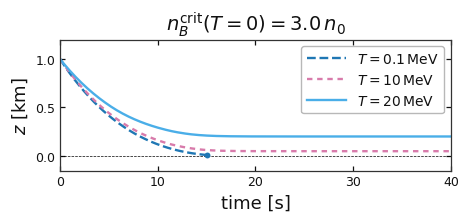

In [88]:
# Tunable plotting parameters
PLOT_TEMPERATURES_MEV = (0.1, 10.0, 20.0)
ENDPOINT_TEMPERATURES_MEV = (0.1,)
FIGURE_SIZE = (4.74, 2.26)
FIGURE_DPI = 100
TITLE_FONT_SIZE = 14
AXIS_LABEL_FONT_SIZE = 13
TICK_LABEL_FONT_SIZE = 9
LEGEND_FONT_SIZE = 10
LINE_WIDTH = 1.7
MARKER_SIZE = 18
SERIES_COLORS = ("#1f77b4", "#d87bab", "#4aaee8")
SERIES_LINE_STYLES = ("--", (0, (2.3, 2.0)), "-")
ZERO_REFERENCE_Y_KM = 0.0
ZERO_REFERENCE_LINE_COLOR = "black"
ZERO_REFERENCE_LINE_STYLE = "--"
ZERO_REFERENCE_LINE_WIDTH = 0.5
MARKER_STYLE = "o"
MARKER_EDGE_WIDTH = 0.0
MARKER_ZORDER = 4
X_LIMITS_S = (0.0, 40)
Y_LIMITS_KM = (-0.15, 1.2)
X_TICK_STEP_S = 10.0
X_TICKS_S = np.arange(0.0, 40 + 0.5 * X_TICK_STEP_S, X_TICK_STEP_S)
Y_TICKS_KM = (0.0, 0.5, 1.0)
TITLE_PAD = 7.0
TICK_DIRECTION = "in"
TICK_LENGTH = 3.5
TICK_WIDTH = 0.9
SHOW_TOP_TICKS = True
SHOW_RIGHT_TICKS = True
SPINE_LINE_WIDTH = 0.9
SPINE_COLOR = "#333333"
TEXT_COLOR = "#111111"
FIGURE_FACE_COLOR = "white"
AXES_FACE_COLOR = "white"
LEGEND_LOCATION = "upper right"
LEGEND_FRAME_ON = True
LEGEND_FRAME_ALPHA = 1.0
LEGEND_FACE_COLOR = "white"
LEGEND_EDGE_COLOR = "#b8b8b8"
LEGEND_HANDLE_LENGTH = 2.8
SUBPLOT_LEFT = 0.12
SUBPLOT_RIGHT = 0.945
SUBPLOT_BOTTOM = 0.25
SUBPLOT_TOP = 0.83
EXPORT_DPI = 100
EXPORT_FACE_COLOR = "white"
PNG_FILENAME = "z-time-evolution.png"
PDF_FILENAME = "z-time-evolution.pdf"

fig, ax = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI, facecolor=FIGURE_FACE_COLOR)
ax.set_facecolor(AXES_FACE_COLOR)
ax.axhline(
    ZERO_REFERENCE_Y_KM,
    color=ZERO_REFERENCE_LINE_COLOR,
    linestyle=ZERO_REFERENCE_LINE_STYLE,
    linewidth=ZERO_REFERENCE_LINE_WIDTH,
)

for temperature_MeV, color, line_style in zip(
    PLOT_TEMPERATURES_MEV,
    SERIES_COLORS,
    SERIES_LINE_STYLES,
):
    temperature_MeV = float(temperature_MeV)
    result = evolution_results[temperature_MeV]
    label = rf"$T={temperature_MeV:g}\,\mathrm{{MeV}}$"
    ax.plot(
        result["t_s"],
        result["z_km"],
        color=color,
        linestyle=line_style,
        linewidth=LINE_WIDTH,
        label=label,
    )
    if temperature_MeV in ENDPOINT_TEMPERATURES_MEV and result["caught_up"]:
        ax.scatter(
            [result["catchup_time_s"]],
            [result["z_km"][-1]],
            color=color,
            marker=MARKER_STYLE,
            s=MARKER_SIZE,
            linewidths=MARKER_EDGE_WIDTH,
            zorder=MARKER_ZORDER,
        )

ax.set_title(
    rf"$n_B^{{\mathrm{{crit}}}}(T=0)={NB_CRIT0_OVER_N0:.1f}\,n_0$",
    fontsize=TITLE_FONT_SIZE,
    color=TEXT_COLOR,
    pad=TITLE_PAD,
)
ax.set_xlabel("time [s]", fontsize=AXIS_LABEL_FONT_SIZE, color=TEXT_COLOR)
ax.set_ylabel(r"$z$ [km]", fontsize=AXIS_LABEL_FONT_SIZE, color=TEXT_COLOR)
ax.set_xlim(0, 40)
ax.set_ylim(*Y_LIMITS_KM)
ax.set_xticks(X_TICKS_S)
ax.set_yticks(Y_TICKS_KM)
ax.tick_params(
    axis="both",
    which="both",
    direction=TICK_DIRECTION,
    top=SHOW_TOP_TICKS,
    right=SHOW_RIGHT_TICKS,
    length=TICK_LENGTH,
    width=TICK_WIDTH,
    labelsize=TICK_LABEL_FONT_SIZE,
    colors=TEXT_COLOR,
)
for spine in ax.spines.values():
    spine.set_linewidth(SPINE_LINE_WIDTH)
    spine.set_color(SPINE_COLOR)

legend = ax.legend(
    loc=LEGEND_LOCATION,
    fontsize=LEGEND_FONT_SIZE,
    frameon=LEGEND_FRAME_ON,
    framealpha=LEGEND_FRAME_ALPHA,
    facecolor=LEGEND_FACE_COLOR,
    edgecolor=LEGEND_EDGE_COLOR,
    handlelength=LEGEND_HANDLE_LENGTH,
)
for text in legend.get_texts():
    text.set_color(TEXT_COLOR)

fig.subplots_adjust(
    left=SUBPLOT_LEFT,
    right=SUBPLOT_RIGHT,
    bottom=SUBPLOT_BOTTOM,
    top=SUBPLOT_TOP,
)
fig.savefig(OUTPUT_DIR / PNG_FILENAME, dpi=EXPORT_DPI, facecolor=EXPORT_FACE_COLOR)
fig.savefig(OUTPUT_DIR / PDF_FILENAME, dpi=EXPORT_DPI, facecolor=EXPORT_FACE_COLOR)
plt.show()


## Analytical samples of $u(0^-)$ versus $z$

This scatter plot reuses the analytical velocity table that drives each $z(t)$ curve. Only points where `analytic_velocity_bound` returned a valid positive eigenvalue are shown; zero-velocity stall-closure points are excluded.


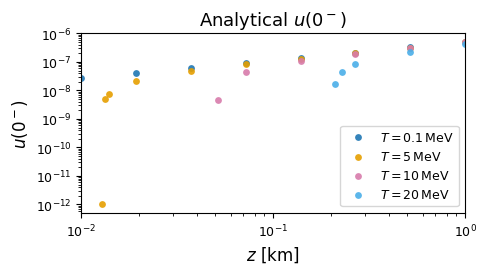

In [6]:
# Tunable plotting parameters
U_SCATTER_FIGURE_SIZE = (4.74, 2.8)
U_SCATTER_FIGURE_DPI = 100
U_SCATTER_COLORS = ("#1f77b4", "#e69f00", "#d87bab", "#4aaee8")
U_SCATTER_MARKER_STYLE = "o"
U_SCATTER_MARKER_SIZE = 24
U_SCATTER_MARKER_ALPHA = 0.9
U_SCATTER_MARKER_EDGE_WIDTH = 0.0
U_SCATTER_X_SCALE = "log"
U_SCATTER_Y_SCALE = "log"
U_SCATTER_X_LIMITS_KM = (Z_STOP_KM, Z0_KM)
U_SCATTER_TITLE = r"Analytical $u(0^-)$"
U_SCATTER_TITLE_FONT_SIZE = 13
U_SCATTER_AXIS_LABEL_FONT_SIZE = 12
U_SCATTER_TICK_LABEL_FONT_SIZE = 9
U_SCATTER_LEGEND_FONT_SIZE = 9
U_SCATTER_LEGEND_LOCATION = "best"
U_SCATTER_GRID_VISIBLE = False
U_SCATTER_SUBPLOT_LEFT = 0.15
U_SCATTER_SUBPLOT_RIGHT = 0.96
U_SCATTER_SUBPLOT_BOTTOM = 0.2
U_SCATTER_SUBPLOT_TOP = 0.84
U_SCATTER_EXPORT_DPI = 100
U_SCATTER_PNG_FILENAME = "analytic-uN-vs-z-scatter.png"
U_SCATTER_PDF_FILENAME = "analytic-uN-vs-z-scatter.pdf"

fig, ax = plt.subplots(figsize=U_SCATTER_FIGURE_SIZE, dpi=U_SCATTER_FIGURE_DPI)
plotted_series_count = 0

for temperature_MeV, color in zip(TEMPERATURES_MEV, U_SCATTER_COLORS):
    temperature_MeV = float(temperature_MeV)
    result = evolution_results[temperature_MeV]
    z_samples_km = np.asarray(result["z_samples_km"], dtype=float)
    u_N_samples = np.asarray(result["u_N_samples"], dtype=float)
    analytic_valid = np.asarray(result["analytic_valid_samples"], dtype=bool)
    computed = analytic_valid & np.isfinite(u_N_samples) & (u_N_samples > 0.0)
    if not np.any(computed):
        print(f"T={temperature_MeV:g} MeV: no successful analytical u(0-) samples")
        continue
    plotted_series_count += 1
    ax.scatter(
        z_samples_km[computed],
        u_N_samples[computed],
        color=color,
        marker=U_SCATTER_MARKER_STYLE,
        s=U_SCATTER_MARKER_SIZE,
        alpha=U_SCATTER_MARKER_ALPHA,
        linewidths=U_SCATTER_MARKER_EDGE_WIDTH,
        label=rf"$T={temperature_MeV:g}\,\mathrm{{MeV}}$",
    )

if plotted_series_count == 0:
    raise RuntimeError("The analytical velocity solver returned no plottable samples")

ax.set_xscale(U_SCATTER_X_SCALE)
ax.set_yscale(U_SCATTER_Y_SCALE)
ax.set_xlim(*U_SCATTER_X_LIMITS_KM)
ax.set_title(U_SCATTER_TITLE, fontsize=U_SCATTER_TITLE_FONT_SIZE)
ax.set_xlabel(r"$z$ [km]", fontsize=U_SCATTER_AXIS_LABEL_FONT_SIZE)
ax.set_ylabel(r"$u(0^-)$", fontsize=U_SCATTER_AXIS_LABEL_FONT_SIZE)
ax.tick_params(axis="both", which="both", labelsize=U_SCATTER_TICK_LABEL_FONT_SIZE)
ax.grid(U_SCATTER_GRID_VISIBLE)
ax.legend(loc=U_SCATTER_LEGEND_LOCATION, fontsize=U_SCATTER_LEGEND_FONT_SIZE)
fig.subplots_adjust(
    left=U_SCATTER_SUBPLOT_LEFT,
    right=U_SCATTER_SUBPLOT_RIGHT,
    bottom=U_SCATTER_SUBPLOT_BOTTOM,
    top=U_SCATTER_SUBPLOT_TOP,
)
fig.savefig(OUTPUT_DIR / U_SCATTER_PNG_FILENAME, dpi=U_SCATTER_EXPORT_DPI)
fig.savefig(OUTPUT_DIR / U_SCATTER_PDF_FILENAME, dpi=U_SCATTER_EXPORT_DPI)
plt.show()


## Analytical cluster velocity contours

The left panel visualizes the two-block adaptive logarithmic-temperature cluster run and uses a logarithmic temperature axis.
The right panel visualizes the updated two-block adaptive linear-temperature `linear-v2` run.
The gray regions are the excluded $A_{\rm boundary}\geq1$ cap and the closed $\Delta h>0$ lobe against the $m=0$ axis.
The purple dash-dot curve marks $\Delta(s/n_B)=0$, and the translucent purple region has $\Delta(s/n_B)<0$ and is excluded for an adiabatic $N\rightarrow Q$ front.


,grid shape,finite velocity cells,missing velocity cells,velocity min [m/s],velocity max [m/s],max A_boundary
0,"(30, 20)",600,0,0.0003,551.714534,0.761747


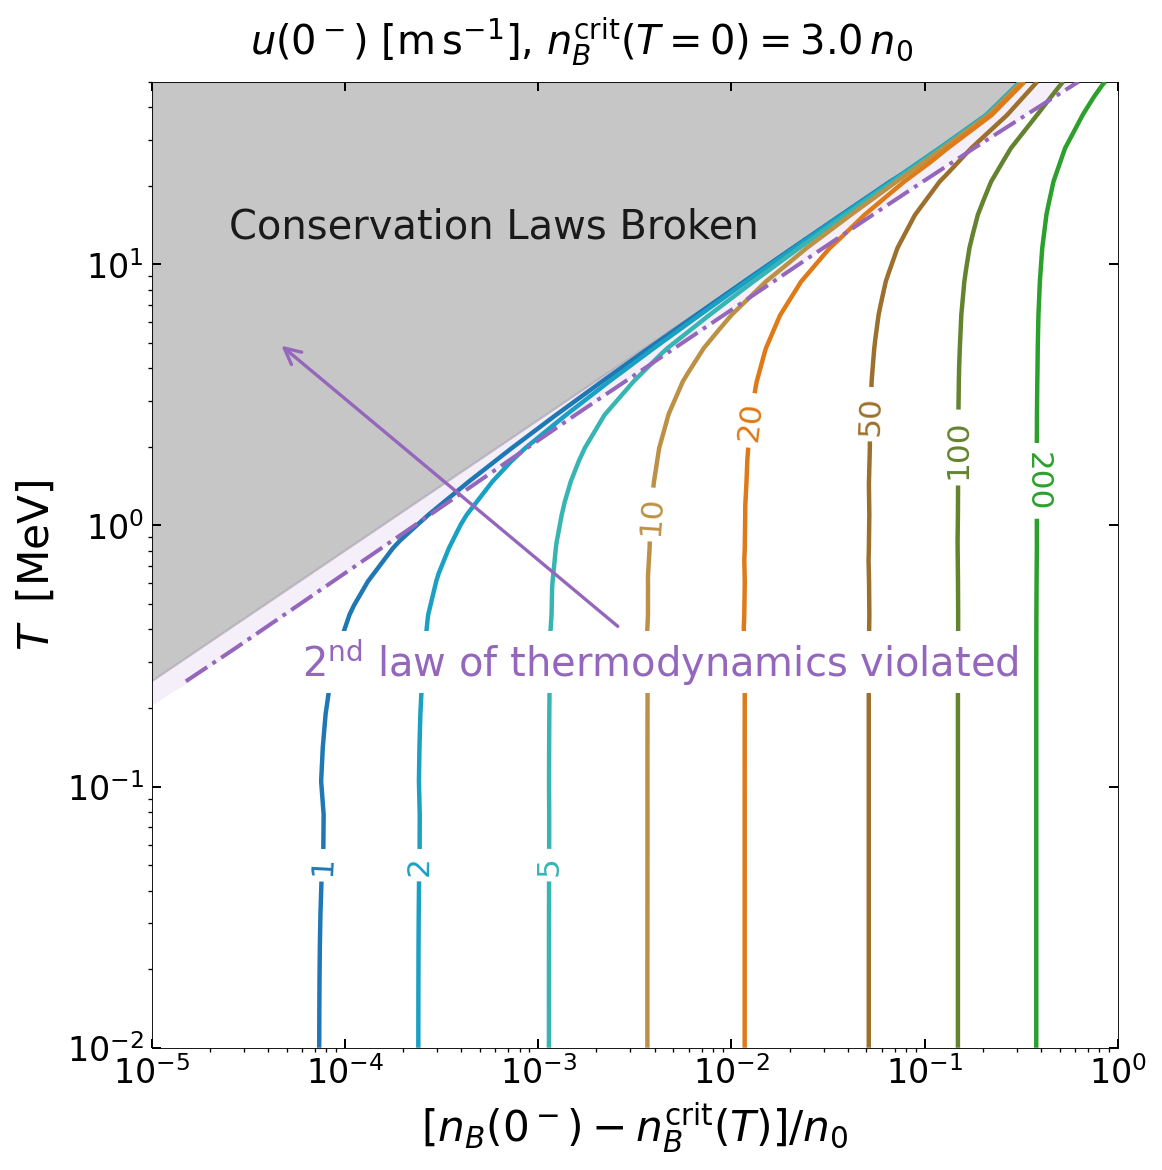

In [85]:
# Tunable plotting parameters
LOG_T_DATA_PATH = "new_paper_calculations/26-07-19/analytic-uN-logTm.npy"
CLUSTER_CONTOUR_OUTPUT_DIR = "local_analysis_results/26SU-8"
CLUSTER_CONTOUR_PNG_FILENAME = "analytic-logTm-contour-entropy-boundary.png"
CLUSTER_CONTOUR_PDF_FILENAME = "analytic-logTm-contour-entropy-boundary.pdf"
CLUSTER_CONTOUR_FIGURE_SIZE = (7.2, 7.2)
CLUSTER_CONTOUR_FIGURE_DPI = 160
CLUSTER_CONTOUR_EXPORT_DPI = 200
CLUSTER_CONTOUR_CONSTRAINED_LAYOUT = True
CLUSTER_CONTOUR_BACKGROUND_COLOR = "white"
CLUSTER_CONTOUR_X_LIMITS = (1.0e-5, 1.0)
CLUSTER_CONTOUR_X_SCALE = "log"
CLUSTER_CONTOUR_Y_LIMITS_MEV = (1.0e-2, 50.0)
CLUSTER_CONTOUR_Y_SCALE = "log"
CLUSTER_CONTOUR_BOX_ASPECT = 1.0
CLUSTER_CONTOUR_LEVELS_M_S = (1.0, 2.0, 5.0, 10.0, 20.0, 50.0, 100.0, 200.0)
CLUSTER_CONTOUR_CMAP_NAME = "linear_contour_palette"
CLUSTER_CONTOUR_CMAP_ANCHORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c")
CLUSTER_CONTOUR_LINESTYLE = "-"
CLUSTER_CONTOUR_LINE_WIDTH = 2.0
CLUSTER_CONTOUR_LABEL_FONT_SIZE = 14
CLUSTER_CONTOUR_LABEL_INLINE = True
CLUSTER_CONTOUR_LABEL_INLINE_SPACING = 5
CLUSTER_CONTOUR_LABEL_FORMAT = "{:.0f}"
CLUSTER_CONTOUR_MANUAL_LABEL_LEVELS_M_S = (1.0, 2.0, 5.0)
CLUSTER_CONTOUR_MANUAL_LABEL_POSITIONS = (
    (7.4e-5, 5.0e-2),
    (2.38e-4, 5.0e-2),
    (1.125e-3, 5.0e-2),
)
CLUSTER_CONTOUR_ZORDER = 3
CLUSTER_CONTOUR_GAP_BOUNDARY_COLOR = "#d62728"
CLUSTER_CONTOUR_GAP_BOUNDARY_LINE_WIDTH = 1.1
CLUSTER_CONTOUR_GAP_BOUNDARY_LINESTYLE = ":"
CLUSTER_CONTOUR_ENTROPY_BOUNDARY_COLOR = "#9467bd"
CLUSTER_CONTOUR_ENTROPY_BOUNDARY_LINE_WIDTH = 1.8
CLUSTER_CONTOUR_ENTROPY_BOUNDARY_LINESTYLE = "-."
CLUSTER_CONTOUR_ENTROPY_BOUNDARY_LEVEL = 0.0
CLUSTER_CONTOUR_ENTROPY_INVALID_COLOR = "#9467bd"
CLUSTER_CONTOUR_ENTROPY_INVALID_ALPHA = 0.10
CLUSTER_CONTOUR_ENTROPY_INVALID_ZORDER = 1
CLUSTER_CONTOUR_BOUNDARY_ZORDER = 4
CLUSTER_CONTOUR_SHADE_COLOR = "0.72"
CLUSTER_CONTOUR_SHADE_ALPHA = 0.8
CLUSTER_CONTOUR_SHADE_ZORDER = 0
CLUSTER_CONTOUR_GAP_FILL_EXTRAPOLATION_POINTS = 2
CLUSTER_CONTOUR_UNPHYSICAL_LABEL = "Conservation Laws Broken"
CLUSTER_CONTOUR_UNPHYSICAL_LABEL_X = 0.08
CLUSTER_CONTOUR_UNPHYSICAL_LABEL_Y_AXES = 0.87
CLUSTER_CONTOUR_UNPHYSICAL_LABEL_FONT_SIZE = 18
CLUSTER_CONTOUR_UNPHYSICAL_LABEL_COLOR = "0.10"
CLUSTER_CONTOUR_UNPHYSICAL_LABEL_HORIZONTAL_ALIGNMENT = "left"
CLUSTER_CONTOUR_UNPHYSICAL_LABEL_VERTICAL_ALIGNMENT = "top"
CLUSTER_CONTOUR_SECOND_LAW_LABEL = "2$^{\\rm nd}$ law of thermodynamics violated"
CLUSTER_CONTOUR_SECOND_LAW_LABEL_POSITION = (6.0e-5, 3.0e-1)
CLUSTER_CONTOUR_SECOND_LAW_LABEL_FONT_SIZE = 18
CLUSTER_CONTOUR_SECOND_LAW_LABEL_COLOR = "#9467bd"
CLUSTER_CONTOUR_SECOND_LAW_LABEL_HORIZONTAL_ALIGNMENT = "left"
CLUSTER_CONTOUR_SECOND_LAW_LABEL_VERTICAL_ALIGNMENT = "center"
CLUSTER_CONTOUR_SECOND_LAW_LABEL_ZORDER = 5
CLUSTER_CONTOUR_SECOND_LAW_LABEL_BOX_FACE_COLOR = "white"
CLUSTER_CONTOUR_SECOND_LAW_LABEL_BOX_EDGE_COLOR = "none"
CLUSTER_CONTOUR_SECOND_LAW_LABEL_BOX_ALPHA = 1.0
CLUSTER_CONTOUR_SECOND_LAW_LABEL_BOX_STYLE = "square,pad=0.15"
CLUSTER_CONTOUR_SECOND_LAW_ARROW_TARGET = (4.5e-5, 5.0)
CLUSTER_CONTOUR_SECOND_LAW_ARROW_STYLE = "->"
CLUSTER_CONTOUR_SECOND_LAW_ARROW_COLOR = "#9467bd"
CLUSTER_CONTOUR_SECOND_LAW_ARROW_LINE_WIDTH = 1.5
CLUSTER_CONTOUR_SECOND_LAW_ARROW_SHRINK_A = 3.0
CLUSTER_CONTOUR_SECOND_LAW_ARROW_SHRINK_B = 2.0
CLUSTER_CONTOUR_SECOND_LAW_ARROW_CONNECTION_STYLE = "arc3,rad=0.0"
#CLUSTER_CONTOUR_PANEL_TITLE = r"Adaptive logarithmic $T$ and $m$ mesh"
#CLUSTER_CONTOUR_PANEL_TITLE_FONT_SIZE = 18
#CLUSTER_CONTOUR_PANEL_TITLE_PAD = 7
CLUSTER_CONTOUR_SUPTITLE_FONT_SIZE = 18
CLUSTER_CONTOUR_AXIS_LABEL_FONT_SIZE = 19
CLUSTER_CONTOUR_TICK_LABEL_FONT_SIZE = 15
CLUSTER_CONTOUR_TICK_DIRECTION = "in"
CLUSTER_CONTOUR_TICKS_TOP = True
CLUSTER_CONTOUR_TICKS_RIGHT = True
CLUSTER_CONTOUR_TICK_LENGTH = 4.0
CLUSTER_CONTOUR_TICK_WIDTH = 0.9
CLUSTER_CONTOUR_SPINE_LINE_WIDTH = 0.4
CLUSTER_CONTOUR_LEGEND_FONT_SIZE = 10
CLUSTER_CONTOUR_LEGEND_LOCATION = "lower right"
CLUSTER_CONTOUR_LEGEND_FRAME_ALPHA = 0.92
CLUSTER_CONTOUR_X_LABEL = r"$[n_B(0^-)-n_B^{\rm crit}(T)]/n_0$"
CLUSTER_CONTOUR_Y_LABEL = r"$T\;\; \rm{[MeV]}$"
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from pathlib import Path
CLUSTER_CONTOUR_CMAP = LinearSegmentedColormap.from_list(
    CLUSTER_CONTOUR_CMAP_NAME,
    CLUSTER_CONTOUR_CMAP_ANCHORS,
    N=len(CLUSTER_CONTOUR_LEVELS_M_S),
)
CLUSTER_CONTOUR_COLORS = tuple(
    CLUSTER_CONTOUR_CMAP(
        np.linspace(0.0, 1.0, len(CLUSTER_CONTOUR_LEVELS_M_S))
    )
)
DATA_PATH = Path(LOG_T_DATA_PATH)
CLUSTER_CONTOUR_OUTPUT_DIR = Path(CLUSTER_CONTOUR_OUTPUT_DIR)
payload = np.load(DATA_PATH, allow_pickle=True).item()
expected_metadata = {
    "temperature_axis_scale": "log",
    "metastability_axis_scale": "log",
    "mesh_layout": "single_block_logT_adaptive_logm",
    "interface_fraction_mode": "extreme_endothermic",
}
for key, expected in expected_metadata.items():
    if payload.get(key) != expected:
        raise ValueError(f"Expected {key}={expected!r} in {DATA_PATH}, got {payload.get(key)!r}")
metastability_grid = np.asarray(payload["metastability_grid"], dtype=float)
temperature_grid_MeV = np.asarray(payload["temperature_grid"], dtype=float)
velocity_grid_m_s = np.asarray(payload["velocity_grid_m_s"], dtype=float)
entropy_jump = np.asarray(payload["entropy_jump_grid"], dtype=float)
if not (
    metastability_grid.shape
    == temperature_grid_MeV.shape
    == velocity_grid_m_s.shape
    == entropy_jump.shape
):
    raise ValueError("Saved log-T/log-m grids do not have matching shapes")
finite_velocity = (
    np.isfinite(metastability_grid)
    & np.isfinite(temperature_grid_MeV)
    & np.isfinite(velocity_grid_m_s)
    & (velocity_grid_m_s > 0.0)
)
if not np.any(finite_velocity):
    raise ValueError(f"No finite positive analytical velocities in {DATA_PATH}")
display(
    pd.DataFrame(
        [
            {
                "grid shape": str(velocity_grid_m_s.shape),
                "finite velocity cells": int(np.count_nonzero(finite_velocity)),
                "missing velocity cells": int(velocity_grid_m_s.size - np.count_nonzero(finite_velocity)),
                "velocity min [m/s]": float(np.nanmin(velocity_grid_m_s[finite_velocity])),
                "velocity max [m/s]": float(np.nanmax(velocity_grid_m_s[finite_velocity])),
                "max A_boundary": float(payload["A_diagnostic_max"]),
            }
        ]
    )
)
fig, ax = plt.subplots(
    figsize=CLUSTER_CONTOUR_FIGURE_SIZE,
    dpi=CLUSTER_CONTOUR_FIGURE_DPI,
    constrained_layout=CLUSTER_CONTOUR_CONSTRAINED_LAYOUT,
    facecolor=CLUSTER_CONTOUR_BACKGROUND_COLOR,
)
ax.set_facecolor(CLUSTER_CONTOUR_BACKGROUND_COLOR)
ax.set_xscale(CLUSTER_CONTOUR_X_SCALE)
ax.set_yscale(CLUSTER_CONTOUR_Y_SCALE)
ax.set_xlim(*CLUSTER_CONTOUR_X_LIMITS)
ax.set_ylim(*CLUSTER_CONTOUR_Y_LIMITS_MEV)
ax.set_box_aspect(CLUSTER_CONTOUR_BOX_ASPECT)
temperature_values_MeV = np.asarray(payload["temperature_values"], dtype=float)
gap_boundary_metastability = np.asarray(payload["gap_boundary_metastability_values"], dtype=float)
finite_gap_boundary = (
    np.isfinite(temperature_values_MeV)
    & np.isfinite(gap_boundary_metastability)
    & (gap_boundary_metastability > CLUSTER_CONTOUR_X_LIMITS[0])
)
gap_temperature_MeV = temperature_values_MeV[finite_gap_boundary]
gap_metastability = gap_boundary_metastability[finite_gap_boundary]
gap_order = np.argsort(gap_temperature_MeV)
gap_temperature_MeV = gap_temperature_MeV[gap_order]
gap_metastability = gap_metastability[gap_order]
if gap_temperature_MeV.size:
    gap_fill_temperature_MeV = gap_temperature_MeV
    gap_fill_metastability = gap_metastability
    if (
        gap_temperature_MeV.size >= CLUSTER_CONTOUR_GAP_FILL_EXTRAPOLATION_POINTS
        and gap_metastability[0] > CLUSTER_CONTOUR_X_LIMITS[0]
    ):
        fit_count = CLUSTER_CONTOUR_GAP_FILL_EXTRAPOLATION_POINTS
        log_slope, log_intercept = np.polyfit(
            np.log(gap_metastability[:fit_count]),
            np.log(gap_temperature_MeV[:fit_count]),
            1,
        )
        gap_temperature_at_x_min = float(
            np.exp(log_slope * np.log(CLUSTER_CONTOUR_X_LIMITS[0]) + log_intercept)
        )
        gap_fill_temperature_MeV = np.concatenate(
            ([gap_temperature_at_x_min], gap_temperature_MeV)
        )
        gap_fill_metastability = np.concatenate(
            ([CLUSTER_CONTOUR_X_LIMITS[0]], gap_metastability)
        )
    ax.fill_betweenx(
        gap_fill_temperature_MeV,
        CLUSTER_CONTOUR_X_LIMITS[0],
        gap_fill_metastability,
        color=CLUSTER_CONTOUR_SHADE_COLOR,
        alpha=CLUSTER_CONTOUR_SHADE_ALPHA,
        zorder=CLUSTER_CONTOUR_SHADE_ZORDER,
    )
level_to_color = dict(zip(CLUSTER_CONTOUR_LEVELS_M_S, CLUSTER_CONTOUR_COLORS))
available_levels = [
    float(level)
    for level in CLUSTER_CONTOUR_LEVELS_M_S
    if np.nanmin(velocity_grid_m_s[finite_velocity])
    <= float(level)
    <= np.nanmax(velocity_grid_m_s[finite_velocity])
]
contour = ax.contour(
    metastability_grid,
    temperature_grid_MeV,
    np.ma.masked_where(~finite_velocity, velocity_grid_m_s),
    levels=available_levels,
    colors=[level_to_color[level] for level in available_levels],
    linewidths=CLUSTER_CONTOUR_LINE_WIDTH,
    linestyles=CLUSTER_CONTOUR_LINESTYLE,
    zorder=CLUSTER_CONTOUR_ZORDER,
)
automatic_label_levels = [
    level
    for level in contour.levels
    if level not in CLUSTER_CONTOUR_MANUAL_LABEL_LEVELS_M_S
]
if automatic_label_levels:
    ax.clabel(
        contour,
        levels=automatic_label_levels,
        inline=CLUSTER_CONTOUR_LABEL_INLINE,
        inline_spacing=CLUSTER_CONTOUR_LABEL_INLINE_SPACING,
        fontsize=CLUSTER_CONTOUR_LABEL_FONT_SIZE,
        fmt=lambda value: CLUSTER_CONTOUR_LABEL_FORMAT.format(value),
    )
manual_label_levels = [
    level
    for level in CLUSTER_CONTOUR_MANUAL_LABEL_LEVELS_M_S
    if level in contour.levels
]
if manual_label_levels:
    ax.clabel(
        contour,
        levels=manual_label_levels,
        manual=CLUSTER_CONTOUR_MANUAL_LABEL_POSITIONS,
        inline=CLUSTER_CONTOUR_LABEL_INLINE,
        inline_spacing=CLUSTER_CONTOUR_LABEL_INLINE_SPACING,
        fontsize=CLUSTER_CONTOUR_LABEL_FONT_SIZE,
        fmt=lambda value: CLUSTER_CONTOUR_LABEL_FORMAT.format(value),
    )
entropy_finite = finite_velocity & np.isfinite(entropy_jump)
if np.any(entropy_finite):
    entropy_minimum = float(np.nanmin(entropy_jump[entropy_finite]))
    if entropy_minimum < CLUSTER_CONTOUR_ENTROPY_BOUNDARY_LEVEL:
        ax.contourf(
            metastability_grid,
            temperature_grid_MeV,
            np.ma.masked_where(~entropy_finite, entropy_jump),
            levels=(entropy_minimum, CLUSTER_CONTOUR_ENTROPY_BOUNDARY_LEVEL),
            colors=(CLUSTER_CONTOUR_ENTROPY_INVALID_COLOR,),
            alpha=CLUSTER_CONTOUR_ENTROPY_INVALID_ALPHA,
            zorder=CLUSTER_CONTOUR_ENTROPY_INVALID_ZORDER,
        )
entropy_boundary_metastability = np.asarray(
    payload["entropy_boundary_metastability_values"], dtype=float
)
finite_entropy_boundary = (
    np.isfinite(temperature_values_MeV)
    & np.isfinite(entropy_boundary_metastability)
    & (entropy_boundary_metastability > 0.0)
)
entropy_temperature_MeV = temperature_values_MeV[finite_entropy_boundary]
entropy_metastability = entropy_boundary_metastability[finite_entropy_boundary]
entropy_order = np.argsort(entropy_temperature_MeV)
ax.plot(
    entropy_metastability[entropy_order],
    entropy_temperature_MeV[entropy_order],
    color=CLUSTER_CONTOUR_ENTROPY_BOUNDARY_COLOR,
    linewidth=CLUSTER_CONTOUR_ENTROPY_BOUNDARY_LINE_WIDTH,
    linestyle=CLUSTER_CONTOUR_ENTROPY_BOUNDARY_LINESTYLE,
    zorder=CLUSTER_CONTOUR_BOUNDARY_ZORDER,
)
ax.annotate(
    CLUSTER_CONTOUR_SECOND_LAW_LABEL,
    xy=CLUSTER_CONTOUR_SECOND_LAW_ARROW_TARGET,
    xytext=CLUSTER_CONTOUR_SECOND_LAW_LABEL_POSITION,
    fontsize=CLUSTER_CONTOUR_SECOND_LAW_LABEL_FONT_SIZE,
    color=CLUSTER_CONTOUR_SECOND_LAW_LABEL_COLOR,
    ha=CLUSTER_CONTOUR_SECOND_LAW_LABEL_HORIZONTAL_ALIGNMENT,
    va=CLUSTER_CONTOUR_SECOND_LAW_LABEL_VERTICAL_ALIGNMENT,
    zorder=CLUSTER_CONTOUR_SECOND_LAW_LABEL_ZORDER,
    bbox={
        "facecolor": CLUSTER_CONTOUR_SECOND_LAW_LABEL_BOX_FACE_COLOR,
        "edgecolor": CLUSTER_CONTOUR_SECOND_LAW_LABEL_BOX_EDGE_COLOR,
        "alpha": CLUSTER_CONTOUR_SECOND_LAW_LABEL_BOX_ALPHA,
        "boxstyle": CLUSTER_CONTOUR_SECOND_LAW_LABEL_BOX_STYLE,
    },
    arrowprops={
        "arrowstyle": CLUSTER_CONTOUR_SECOND_LAW_ARROW_STYLE,
        "color": CLUSTER_CONTOUR_SECOND_LAW_ARROW_COLOR,
        "linewidth": CLUSTER_CONTOUR_SECOND_LAW_ARROW_LINE_WIDTH,
        "shrinkA": CLUSTER_CONTOUR_SECOND_LAW_ARROW_SHRINK_A,
        "shrinkB": CLUSTER_CONTOUR_SECOND_LAW_ARROW_SHRINK_B,
        "connectionstyle": CLUSTER_CONTOUR_SECOND_LAW_ARROW_CONNECTION_STYLE,
    },
)
ax.set_xlabel(CLUSTER_CONTOUR_X_LABEL, fontsize=CLUSTER_CONTOUR_AXIS_LABEL_FONT_SIZE)
ax.set_ylabel(CLUSTER_CONTOUR_Y_LABEL, fontsize=CLUSTER_CONTOUR_AXIS_LABEL_FONT_SIZE)
ax.tick_params(
    direction=CLUSTER_CONTOUR_TICK_DIRECTION,
    top=CLUSTER_CONTOUR_TICKS_TOP,
    right=CLUSTER_CONTOUR_TICKS_RIGHT,
    length=CLUSTER_CONTOUR_TICK_LENGTH,
    width=CLUSTER_CONTOUR_TICK_WIDTH,
    labelsize=CLUSTER_CONTOUR_TICK_LABEL_FONT_SIZE,
)
for spine in ax.spines.values():
    spine.set_linewidth(CLUSTER_CONTOUR_SPINE_LINE_WIDTH)
if gap_temperature_MeV.size:
    ax.text(
        CLUSTER_CONTOUR_UNPHYSICAL_LABEL_X,
        CLUSTER_CONTOUR_UNPHYSICAL_LABEL_Y_AXES,
        CLUSTER_CONTOUR_UNPHYSICAL_LABEL,
        fontsize=CLUSTER_CONTOUR_UNPHYSICAL_LABEL_FONT_SIZE,
        color=CLUSTER_CONTOUR_UNPHYSICAL_LABEL_COLOR,
        ha=CLUSTER_CONTOUR_UNPHYSICAL_LABEL_HORIZONTAL_ALIGNMENT,
        va=CLUSTER_CONTOUR_UNPHYSICAL_LABEL_VERTICAL_ALIGNMENT,
        zorder=CLUSTER_CONTOUR_SHADE_ZORDER + 1,
        transform=ax.transAxes,
    )
legend_handles = (
    Patch(
        facecolor=CLUSTER_CONTOUR_SHADE_COLOR,
        alpha=CLUSTER_CONTOUR_SHADE_ALPHA,
        label=r"$\Delta h>0$ excluded",
    ),
    Line2D(
        (0.0,),
        (0.0,),
        color=CLUSTER_CONTOUR_GAP_BOUNDARY_COLOR,
        linestyle=CLUSTER_CONTOUR_GAP_BOUNDARY_LINESTYLE,
        linewidth=CLUSTER_CONTOUR_GAP_BOUNDARY_LINE_WIDTH,
        label=r"$\Delta h=0$",
    ),
    Line2D(
        (0.0,),
        (0.0,),
        color=CLUSTER_CONTOUR_ENTROPY_BOUNDARY_COLOR,
        linestyle=CLUSTER_CONTOUR_ENTROPY_BOUNDARY_LINESTYLE,
        linewidth=CLUSTER_CONTOUR_ENTROPY_BOUNDARY_LINE_WIDTH,
        label=r"$\Delta(s/n_B)=0$; $\Delta(s/n_B)<0$ excluded",
    ),
)
fig.suptitle(
    rf"$u(0^-)$ [$\mathrm{{m\,s^{{-1}}}}$], $n_B^{{\rm crit}}(T=0)={float(payload['nB_crit0_over_n0']):.1f}\,n_0$",
    fontsize=CLUSTER_CONTOUR_SUPTITLE_FONT_SIZE,
)
CLUSTER_CONTOUR_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(
    CLUSTER_CONTOUR_OUTPUT_DIR / CLUSTER_CONTOUR_PNG_FILENAME,
    dpi=CLUSTER_CONTOUR_EXPORT_DPI,
    facecolor=CLUSTER_CONTOUR_BACKGROUND_COLOR,
)
fig.savefig(
    CLUSTER_CONTOUR_OUTPUT_DIR / CLUSTER_CONTOUR_PDF_FILENAME,
    facecolor=CLUSTER_CONTOUR_BACKGROUND_COLOR,
)
plt.show()



,block,grid shape,finite velocity cells,missing velocity cells,velocity min [m/s],velocity max [m/s]
0,low,"(30, 20)",600,0,0.861779,1898.232970
1,high,"(12, 20)",240,0,581.282813,228741.098382


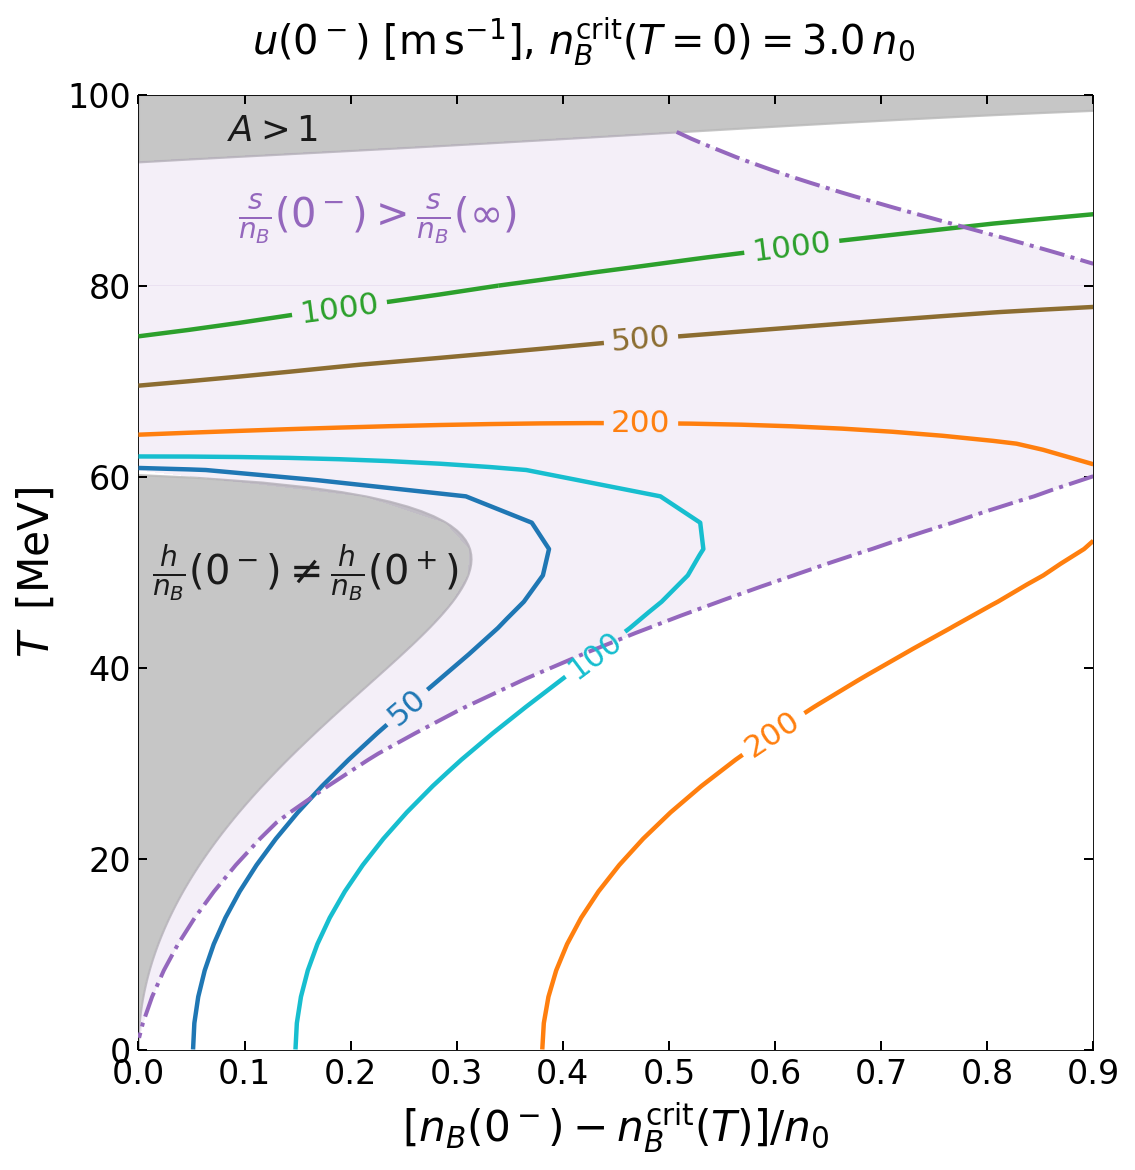

In [1]:
# Tunable plotting parameters
LINEAR_T_DATA_PATH = "new_paper_calculations/26-07-18/uN-two-block-adaptive-contour-linear-v2.npy"
CLUSTER_CONTOUR_OUTPUT_DIR = "local_analysis_results/26SU-8"
CLUSTER_CONTOUR_PNG_FILENAME = "analytic-two-block-contour-linear-v2-entropy-boundary.png"
CLUSTER_CONTOUR_PDF_FILENAME = "analytic-two-block-contour-linear-v2-entropy-boundary.pdf"
CLUSTER_CONTOUR_FIGURE_SIZE = (7.2, 7.2)
CLUSTER_CONTOUR_FIGURE_DPI = 160
CLUSTER_CONTOUR_EXPORT_DPI = 200
CLUSTER_CONTOUR_CONSTRAINED_LAYOUT = True
CLUSTER_CONTOUR_BACKGROUND_COLOR = "white"
CLUSTER_CONTOUR_X_LIMITS = (0.0, 0.9)
CLUSTER_CONTOUR_Y_LIMITS_MEV = (0.0, 100.0)
CLUSTER_CONTOUR_Y_SCALE = "linear"
CLUSTER_CONTOUR_BOX_ASPECT = 1.0
CLUSTER_CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0)
CLUSTER_CONTOUR_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c")
CLUSTER_CONTOUR_LINESTYLE = "-"
CLUSTER_CONTOUR_LINE_WIDTH = 2.0
CLUSTER_CONTOUR_LABEL_FONT_SIZE = 14
CLUSTER_CONTOUR_LABEL_INLINE = True
CLUSTER_CONTOUR_LABEL_INLINE_SPACING = 5
CLUSTER_CONTOUR_LABEL_FORMAT = "{:.0f}"
CLUSTER_CONTOUR_ZORDER = 3
CLUSTER_CONTOUR_A_BOUNDARY_COLOR = "0.35"
CLUSTER_CONTOUR_A_BOUNDARY_LINE_WIDTH = 1.1
CLUSTER_CONTOUR_A_BOUNDARY_LINESTYLE = "--"
CLUSTER_CONTOUR_GAP_BOUNDARY_COLOR = "#d62728"
CLUSTER_CONTOUR_GAP_BOUNDARY_LINE_WIDTH = 1.1
CLUSTER_CONTOUR_GAP_BOUNDARY_LINESTYLE = ":"
CLUSTER_CONTOUR_ENTROPY_BOUNDARY_COLOR = "#9467bd"
CLUSTER_CONTOUR_ENTROPY_BOUNDARY_LINE_WIDTH = 1.8
CLUSTER_CONTOUR_ENTROPY_BOUNDARY_LINESTYLE = "-."
CLUSTER_CONTOUR_ENTROPY_BOUNDARY_LEVEL = 0.0
CLUSTER_CONTOUR_ENTROPY_INVALID_COLOR = "#9467bd"
CLUSTER_CONTOUR_ENTROPY_INVALID_ALPHA = 0.10
CLUSTER_CONTOUR_ENTROPY_INVALID_ZORDER = 1
CLUSTER_CONTOUR_BOUNDARY_ZORDER = 4
CLUSTER_CONTOUR_SHADE_COLOR = "0.72"
CLUSTER_CONTOUR_SHADE_ALPHA = 0.8
CLUSTER_CONTOUR_SHADE_ZORDER = 0
CLUSTER_CONTOUR_UNPHYSICAL_LABEL = r"$A>1$"
CLUSTER_CONTOUR_UNPHYSICAL_LABEL_X = 0.14
CLUSTER_CONTOUR_UNPHYSICAL_LABEL_Y_AXES = 0.98
CLUSTER_CONTOUR_UNPHYSICAL_LABEL_FONT_SIZE = 16
CLUSTER_CONTOUR_UNPHYSICAL_LABEL_COLOR = "0.10"
CLUSTER_CONTOUR_UNPHYSICAL_LABEL_HORIZONTAL_ALIGNMENT = "center"
CLUSTER_CONTOUR_UNPHYSICAL_LABEL_VERTICAL_ALIGNMENT = "top"
CLUSTER_CONTOUR_CONSERVATION_LABEL = r"$\frac{h}{n_B}({0^-}) \neq \frac{h}{n_B}({0^+})$"
CLUSTER_CONTOUR_CONSERVATION_LABEL_X_AXES = 0.175
CLUSTER_CONTOUR_CONSERVATION_LABEL_Y_AXES = 0.50
CLUSTER_CONTOUR_CONSERVATION_LABEL_FONT_SIZE = 18
CLUSTER_CONTOUR_CONSERVATION_LABEL_COLOR = "0.10"
CLUSTER_CONTOUR_CONSERVATION_LABEL_HORIZONTAL_ALIGNMENT = "center"
CLUSTER_CONTOUR_CONSERVATION_LABEL_VERTICAL_ALIGNMENT = "center"
CLUSTER_CONTOUR_SECOND_LAW_LABEL = r"$\frac{s}{n_B}({0^-}) > \frac{s}{n_B}({\infty})$"
CLUSTER_CONTOUR_SECOND_LAW_LABEL_X_AXES = 0.25
CLUSTER_CONTOUR_SECOND_LAW_LABEL_Y_AXES = 0.87
CLUSTER_CONTOUR_SECOND_LAW_LABEL_FONT_SIZE = 18
CLUSTER_CONTOUR_SECOND_LAW_LABEL_COLOR = "#9467bd"
CLUSTER_CONTOUR_SECOND_LAW_LABEL_HORIZONTAL_ALIGNMENT = "center"
CLUSTER_CONTOUR_SECOND_LAW_LABEL_VERTICAL_ALIGNMENT = "center"
CLUSTER_CONTOUR_ANNOTATION_ZORDER = 5
CLUSTER_CONTOUR_PANEL_TITLE = r"Two-block adaptive linear $T$ mesh (v2)"
CLUSTER_CONTOUR_PANEL_TITLE_FONT_SIZE = 18
CLUSTER_CONTOUR_PANEL_TITLE_PAD = 7
CLUSTER_CONTOUR_SUPTITLE_FONT_SIZE = 18
CLUSTER_CONTOUR_AXIS_LABEL_FONT_SIZE = 19
CLUSTER_CONTOUR_TICK_LABEL_FONT_SIZE = 15
CLUSTER_CONTOUR_TICK_DIRECTION = "in"
CLUSTER_CONTOUR_TICKS_TOP = True
CLUSTER_CONTOUR_TICKS_RIGHT = True
CLUSTER_CONTOUR_TICK_LENGTH = 4.0
CLUSTER_CONTOUR_TICK_WIDTH = 0.9
CLUSTER_CONTOUR_SPINE_LINE_WIDTH = 0.4
CLUSTER_CONTOUR_LEGEND_FONT_SIZE = 10
CLUSTER_CONTOUR_LEGEND_LOCATION = "lower right"
CLUSTER_CONTOUR_LEGEND_FRAME_ALPHA = 0.92
CLUSTER_CONTOUR_X_LABEL = r"$[n_B(0^-)-n_B^{\rm crit}(T)]/n_0$"
CLUSTER_CONTOUR_Y_LABEL = r"$T\;\; \rm{[MeV]}$"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from pathlib import Path

DATA_PATH = Path(LINEAR_T_DATA_PATH)
CLUSTER_CONTOUR_OUTPUT_DIR = Path(CLUSTER_CONTOUR_OUTPUT_DIR)


def entropy_per_baryon_jump_grid(payload, block_name):
    grid_shape = np.asarray(payload[f"{block_name}_velocity_grid_m_s"]).shape
    entropy_jump = np.full(grid_shape, np.nan, dtype=float)
    for record in payload["records"]:
        if record.get("mesh_block") != block_name:
            continue
        row_index = record.get("block_row_index")
        col_index = record.get("block_col_index")
        values = np.asarray(
            [
                record.get("T_MeV", np.nan),
                record.get("T_Q_MeV", np.nan),
                record.get("h_over_nB_N_MeV", np.nan),
                record.get("muB_N_MeV", np.nan),
                record.get("h_over_nB_Q_MeV", np.nan),
                record.get("muB_Q_MeV", np.nan),
            ],
            dtype=float,
        )
        if row_index is None or col_index is None or not np.all(np.isfinite(values)):
            continue
        T_N_MeV, T_Q_MeV, h_N_over_nB, muB_N, h_Q_over_nB, muB_Q = values
        if T_N_MeV <= 0.0 or T_Q_MeV <= 0.0:
            continue
        entropy_jump[int(row_index), int(col_index)] = (
            (h_Q_over_nB - muB_Q) / T_Q_MeV
            - (h_N_over_nB - muB_N) / T_N_MeV
        )
    if block_name == "high" and not np.any(np.isfinite(entropy_jump[0, :])):
        low_entropy_jump = entropy_per_baryon_jump_grid(payload, "low")
        if low_entropy_jump.shape[1] == entropy_jump.shape[1]:
            entropy_jump[0, :] = low_entropy_jump[-1, :]
    return entropy_jump


payload = np.load(DATA_PATH, allow_pickle=True).item()
if payload.get("temperature_mesh") != "adaptive_linear":
    raise ValueError(
        f"Expected 'adaptive_linear' in {DATA_PATH}, got "
        f"{payload.get('temperature_mesh')!r}"
    )
if payload.get("mesh_layout") != "two_block_orthogonal_adaptive":
    raise ValueError(f"Expected the two-block mesh layout in {DATA_PATH}")
if payload.get("interface_fraction_mode") != "extreme_endothermic":
    raise ValueError(f"Expected extreme_endothermic in {DATA_PATH}")

block_data = []
diagnostic_rows = []
for block_name in ("low", "high"):
    metastability_grid = np.asarray(payload[f"{block_name}_metastability_grid"], dtype=float)
    temperature_grid_MeV = np.asarray(payload[f"{block_name}_temperature_grid"], dtype=float)
    velocity_grid_m_s = np.asarray(payload[f"{block_name}_velocity_grid_m_s"], dtype=float)
    finite = (
        np.isfinite(metastability_grid)
        & np.isfinite(temperature_grid_MeV)
        & np.isfinite(velocity_grid_m_s)
        & (velocity_grid_m_s > 0.0)
    )
    if not np.any(finite):
        raise ValueError(f"No finite positive velocities in the {block_name} block")
    block_data.append(
        (block_name, metastability_grid, temperature_grid_MeV, velocity_grid_m_s, finite)
    )
    diagnostic_rows.append(
        {
            "block": block_name,
            "grid shape": str(velocity_grid_m_s.shape),
            "finite velocity cells": int(np.count_nonzero(finite)),
            "missing velocity cells": int(velocity_grid_m_s.size - np.count_nonzero(finite)),
            "velocity min [m/s]": float(np.nanmin(velocity_grid_m_s[finite])),
            "velocity max [m/s]": float(np.nanmax(velocity_grid_m_s[finite])),
        }
    )

display(pd.DataFrame(diagnostic_rows))

fig, ax = plt.subplots(
    figsize=CLUSTER_CONTOUR_FIGURE_SIZE,
    dpi=CLUSTER_CONTOUR_FIGURE_DPI,
    constrained_layout=CLUSTER_CONTOUR_CONSTRAINED_LAYOUT,
    facecolor=CLUSTER_CONTOUR_BACKGROUND_COLOR,
)
ax.set_facecolor(CLUSTER_CONTOUR_BACKGROUND_COLOR)
ax.set_yscale(CLUSTER_CONTOUR_Y_SCALE)
ax.set_xlim(*CLUSTER_CONTOUR_X_LIMITS)
ax.set_ylim(*CLUSTER_CONTOUR_Y_LIMITS_MEV)
ax.set_box_aspect(CLUSTER_CONTOUR_BOX_ASPECT)

A_boundary_metastability = np.asarray(payload["A_boundary_metastability_values"], dtype=float)
A_boundary_temperature_MeV = np.asarray(payload["A_boundary_temperature_values"], dtype=float)
finite_A_boundary = np.isfinite(A_boundary_metastability) & np.isfinite(A_boundary_temperature_MeV)
A_boundary_order = np.argsort(A_boundary_metastability[finite_A_boundary])
A_boundary_metastability = A_boundary_metastability[finite_A_boundary][A_boundary_order]
A_boundary_temperature_MeV = A_boundary_temperature_MeV[finite_A_boundary][A_boundary_order]
ax.fill_between(
    A_boundary_metastability,
    A_boundary_temperature_MeV,
    CLUSTER_CONTOUR_Y_LIMITS_MEV[1],
    color=CLUSTER_CONTOUR_SHADE_COLOR,
    alpha=CLUSTER_CONTOUR_SHADE_ALPHA,
    zorder=CLUSTER_CONTOUR_SHADE_ZORDER,
)

gap_boundary_metastability = np.asarray(payload["gap_boundary_metastability_values"], dtype=float)
gap_boundary_temperature_MeV = np.asarray(payload["gap_boundary_temperature_values"], dtype=float)
finite_gap_boundary = np.isfinite(gap_boundary_metastability) & np.isfinite(gap_boundary_temperature_MeV)
gap_boundary_metastability = gap_boundary_metastability[finite_gap_boundary]
gap_boundary_temperature_MeV = np.clip(
    gap_boundary_temperature_MeV[finite_gap_boundary],
    CLUSTER_CONTOUR_Y_LIMITS_MEV[0],
    CLUSTER_CONTOUR_Y_LIMITS_MEV[1],
)
ax.fill(
    gap_boundary_metastability,
    gap_boundary_temperature_MeV,
    color=CLUSTER_CONTOUR_SHADE_COLOR,
    alpha=CLUSTER_CONTOUR_SHADE_ALPHA,
    zorder=CLUSTER_CONTOUR_SHADE_ZORDER,
)

level_to_color = dict(zip(CLUSTER_CONTOUR_LEVELS_M_S, CLUSTER_CONTOUR_COLORS))
for _, metastability_grid, temperature_grid_MeV, velocity_grid_m_s, finite in block_data:
    available_levels = [
        float(level)
        for level in CLUSTER_CONTOUR_LEVELS_M_S
        if np.nanmin(velocity_grid_m_s[finite]) <= float(level) <= np.nanmax(velocity_grid_m_s[finite])
    ]
    if not available_levels:
        continue
    contour = ax.contour(
        metastability_grid,
        temperature_grid_MeV,
        np.ma.masked_where(~finite, velocity_grid_m_s),
        levels=available_levels,
        colors=[level_to_color[level] for level in available_levels],
        linewidths=CLUSTER_CONTOUR_LINE_WIDTH,
        linestyles=CLUSTER_CONTOUR_LINESTYLE,
        zorder=CLUSTER_CONTOUR_ZORDER,
    )
    ax.clabel(
        contour,
        contour.levels,
        inline=CLUSTER_CONTOUR_LABEL_INLINE,
        inline_spacing=CLUSTER_CONTOUR_LABEL_INLINE_SPACING,
        fontsize=CLUSTER_CONTOUR_LABEL_FONT_SIZE,
        fmt=lambda value: CLUSTER_CONTOUR_LABEL_FORMAT.format(value),
    )

for block_name, metastability_grid, temperature_grid_MeV, _, finite in block_data:
    entropy_jump = entropy_per_baryon_jump_grid(payload, block_name)
    entropy_finite = finite & np.isfinite(entropy_jump)
    if np.any(entropy_finite):
        entropy_minimum = float(np.nanmin(entropy_jump[entropy_finite]))
        if entropy_minimum < CLUSTER_CONTOUR_ENTROPY_BOUNDARY_LEVEL:
            ax.contourf(
                metastability_grid,
                temperature_grid_MeV,
                np.ma.masked_where(~entropy_finite, entropy_jump),
                levels=(entropy_minimum, CLUSTER_CONTOUR_ENTROPY_BOUNDARY_LEVEL),
                colors=(CLUSTER_CONTOUR_ENTROPY_INVALID_COLOR,),
                alpha=CLUSTER_CONTOUR_ENTROPY_INVALID_ALPHA,
                zorder=CLUSTER_CONTOUR_ENTROPY_INVALID_ZORDER,
            )
    if (
        np.any(entropy_finite)
        and np.nanmin(entropy_jump[entropy_finite]) <= CLUSTER_CONTOUR_ENTROPY_BOUNDARY_LEVEL
        and np.nanmax(entropy_jump[entropy_finite]) >= CLUSTER_CONTOUR_ENTROPY_BOUNDARY_LEVEL
    ):
        ax.contour(
            metastability_grid,
            temperature_grid_MeV,
            np.ma.masked_where(~entropy_finite, entropy_jump),
            levels=(CLUSTER_CONTOUR_ENTROPY_BOUNDARY_LEVEL,),
            colors=(CLUSTER_CONTOUR_ENTROPY_BOUNDARY_COLOR,),
            linewidths=CLUSTER_CONTOUR_ENTROPY_BOUNDARY_LINE_WIDTH,
            linestyles=CLUSTER_CONTOUR_ENTROPY_BOUNDARY_LINESTYLE,
            zorder=CLUSTER_CONTOUR_BOUNDARY_ZORDER,
        )


ax.set_xlabel(CLUSTER_CONTOUR_X_LABEL, fontsize=CLUSTER_CONTOUR_AXIS_LABEL_FONT_SIZE)
ax.set_ylabel(CLUSTER_CONTOUR_Y_LABEL, fontsize=CLUSTER_CONTOUR_AXIS_LABEL_FONT_SIZE)
ax.tick_params(
    direction=CLUSTER_CONTOUR_TICK_DIRECTION,
    top=CLUSTER_CONTOUR_TICKS_TOP,
    right=CLUSTER_CONTOUR_TICKS_RIGHT,
    length=CLUSTER_CONTOUR_TICK_LENGTH,
    width=CLUSTER_CONTOUR_TICK_WIDTH,
    labelsize=CLUSTER_CONTOUR_TICK_LABEL_FONT_SIZE,
)
for spine in ax.spines.values():
    spine.set_linewidth(CLUSTER_CONTOUR_SPINE_LINE_WIDTH)
ax.text(
    CLUSTER_CONTOUR_UNPHYSICAL_LABEL_X,
    CLUSTER_CONTOUR_UNPHYSICAL_LABEL_Y_AXES,
    CLUSTER_CONTOUR_UNPHYSICAL_LABEL,
    fontsize=CLUSTER_CONTOUR_UNPHYSICAL_LABEL_FONT_SIZE,
    color=CLUSTER_CONTOUR_UNPHYSICAL_LABEL_COLOR,
    ha=CLUSTER_CONTOUR_UNPHYSICAL_LABEL_HORIZONTAL_ALIGNMENT,
    va=CLUSTER_CONTOUR_UNPHYSICAL_LABEL_VERTICAL_ALIGNMENT,
    zorder=CLUSTER_CONTOUR_SHADE_ZORDER + 1,
    transform=ax.transAxes,
)
ax.text(
    CLUSTER_CONTOUR_CONSERVATION_LABEL_X_AXES,
    CLUSTER_CONTOUR_CONSERVATION_LABEL_Y_AXES,
    CLUSTER_CONTOUR_CONSERVATION_LABEL,
    fontsize=CLUSTER_CONTOUR_CONSERVATION_LABEL_FONT_SIZE,
    color=CLUSTER_CONTOUR_CONSERVATION_LABEL_COLOR,
    ha=CLUSTER_CONTOUR_CONSERVATION_LABEL_HORIZONTAL_ALIGNMENT,
    va=CLUSTER_CONTOUR_CONSERVATION_LABEL_VERTICAL_ALIGNMENT,
    zorder=CLUSTER_CONTOUR_ANNOTATION_ZORDER,
    transform=ax.transAxes,
)
ax.text(
    CLUSTER_CONTOUR_SECOND_LAW_LABEL_X_AXES,
    CLUSTER_CONTOUR_SECOND_LAW_LABEL_Y_AXES,
    CLUSTER_CONTOUR_SECOND_LAW_LABEL,
    fontsize=CLUSTER_CONTOUR_SECOND_LAW_LABEL_FONT_SIZE,
    color=CLUSTER_CONTOUR_SECOND_LAW_LABEL_COLOR,
    ha=CLUSTER_CONTOUR_SECOND_LAW_LABEL_HORIZONTAL_ALIGNMENT,
    va=CLUSTER_CONTOUR_SECOND_LAW_LABEL_VERTICAL_ALIGNMENT,
    zorder=CLUSTER_CONTOUR_ANNOTATION_ZORDER,
    transform=ax.transAxes,
)

legend_handles = (
    Patch(
        facecolor=CLUSTER_CONTOUR_SHADE_COLOR,
        alpha=CLUSTER_CONTOUR_SHADE_ALPHA,
        label="outside safe domain",
    ),
    Line2D(
        (0.0,),
        (0.0,),
        color=CLUSTER_CONTOUR_A_BOUNDARY_COLOR,
        linestyle=CLUSTER_CONTOUR_A_BOUNDARY_LINESTYLE,
        linewidth=CLUSTER_CONTOUR_A_BOUNDARY_LINE_WIDTH,
        label=r"$A_{\rm boundary}=1$",
    ),
    Line2D(
        (0.0,),
        (0.0,),
        color=CLUSTER_CONTOUR_GAP_BOUNDARY_COLOR,
        linestyle=CLUSTER_CONTOUR_GAP_BOUNDARY_LINESTYLE,
        linewidth=CLUSTER_CONTOUR_GAP_BOUNDARY_LINE_WIDTH,
        label=r"$\Delta h=0$",
    ),
    Line2D(
        (0.0,),
        (0.0,),
        color=CLUSTER_CONTOUR_ENTROPY_BOUNDARY_COLOR,
        linestyle=CLUSTER_CONTOUR_ENTROPY_BOUNDARY_LINESTYLE,
        linewidth=CLUSTER_CONTOUR_ENTROPY_BOUNDARY_LINE_WIDTH,
        label=r"$\Delta(s/n_B)=0$; $\Delta(s/n_B)<0$ excluded",
    ),
)

fig.suptitle(
    rf"$u(0^-)$ [$\mathrm{{m\,s^{{-1}}}}$], $n_B^{{\rm crit}}(T=0)={float(payload['nB_crit0_over_n0']):.1f}\,n_0$",
    fontsize=CLUSTER_CONTOUR_SUPTITLE_FONT_SIZE,
)
CLUSTER_CONTOUR_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(
    CLUSTER_CONTOUR_OUTPUT_DIR / CLUSTER_CONTOUR_PNG_FILENAME,
    dpi=CLUSTER_CONTOUR_EXPORT_DPI,
    facecolor=CLUSTER_CONTOUR_BACKGROUND_COLOR,
)
fig.savefig(
    CLUSTER_CONTOUR_OUTPUT_DIR / CLUSTER_CONTOUR_PDF_FILENAME,
    facecolor=CLUSTER_CONTOUR_BACKGROUND_COLOR,
)
plt.show()



,T_N_MeV,metastability,muB_N_MeV,muB_Q_plot_MeV,muB_Q_source,enthalpy_gap_MeV,moving_solution,T_Q_endpoint_MeV,u_N_m_s
0,20.0,0.03,1167.453706,1162.672289,solved static coexistence (m=0),2.084425,False,NaN,NaN
1,20.0,0.10,1178.768449,1184.448348,solved moving endpoint,-2.547855,True,8.24651,38.682113


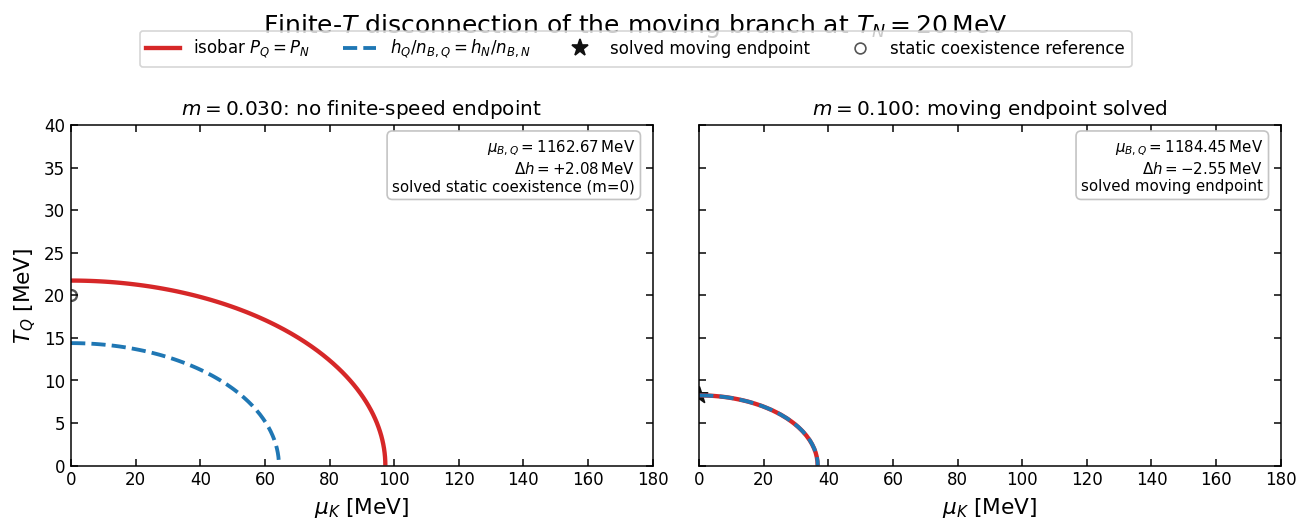

In [14]:
# Tunable plotting parameters
ENTHALPY_UPSTREAM_T_N_MEV = 20.0
ENTHALPY_METASTABILITIES = (0.03, 0.10)
ENTHALPY_INTERFACE_FRACTION_MODE = "LTE"
ENTHALPY_MU_K_LIMITS_MEV = (0.0, 180.0)
ENTHALPY_T_Q_LIMITS_MEV = (0.0, 40.0)
ENTHALPY_MU_K_GRID_COUNT = 121
ENTHALPY_T_Q_GRID_COUNT = 81
ENTHALPY_FIGURE_SIZE = (11.2, 4.5)
ENTHALPY_FIGURE_DPI = 120
ENTHALPY_EXPORT_DPI = 180
ENTHALPY_ISOBAR_COLOR = "#d62728"
ENTHALPY_ISOBAR_LINE_STYLE = "-"
ENTHALPY_ISOBAR_LINE_WIDTH = 2.6
ENTHALPY_CONSERVATION_COLOR = "#1f77b4"
ENTHALPY_CONSERVATION_LINE_STYLE = "--"
ENTHALPY_CONSERVATION_LINE_WIDTH = 2.3
ENTHALPY_MOVING_MARKER = "*"
ENTHALPY_MOVING_MARKER_COLOR = "#111111"
ENTHALPY_MOVING_MARKER_SIZE = 105
ENTHALPY_STATIC_MARKER = "o"
ENTHALPY_STATIC_MARKER_EDGE_COLOR = "#555555"
ENTHALPY_STATIC_MARKER_FACE_COLOR = "white"
ENTHALPY_STATIC_MARKER_SIZE = 42
ENTHALPY_STATIC_MARKER_LINE_WIDTH = 1.4
ENTHALPY_AXIS_LABEL_FONT_SIZE = 13
ENTHALPY_TICK_LABEL_FONT_SIZE = 10
ENTHALPY_PANEL_TITLE_FONT_SIZE = 12
ENTHALPY_SUPTITLE_FONT_SIZE = 15
ENTHALPY_ANNOTATION_FONT_SIZE = 9
ENTHALPY_LEGEND_FONT_SIZE = 10
ENTHALPY_LEGEND_LOCATION = "upper center"
ENTHALPY_LEGEND_COLUMNS = 4
ENTHALPY_LEGEND_BBOX = (0.5, 0.96)
ENTHALPY_TICK_DIRECTION = "in"
ENTHALPY_TICK_LENGTH = 4.0
ENTHALPY_TICK_WIDTH = 0.9
ENTHALPY_SHOW_TOP_TICKS = True
ENTHALPY_SHOW_RIGHT_TICKS = True
ENTHALPY_SPINE_LINE_WIDTH = 0.9
ENTHALPY_ANNOTATION_X = 0.97
ENTHALPY_ANNOTATION_Y = 0.96
ENTHALPY_ANNOTATION_HORIZONTAL_ALIGNMENT = "right"
ENTHALPY_ANNOTATION_VERTICAL_ALIGNMENT = "top"
ENTHALPY_ANNOTATION_BOX_STYLE = "round,pad=0.35"
ENTHALPY_ANNOTATION_BOX_FACE_COLOR = "white"
ENTHALPY_ANNOTATION_BOX_EDGE_COLOR = "0.75"
ENTHALPY_ANNOTATION_BOX_ALPHA = 0.92
ENTHALPY_SUBPLOT_LEFT = 0.08
ENTHALPY_SUBPLOT_RIGHT = 0.98
ENTHALPY_SUBPLOT_BOTTOM = 0.14
ENTHALPY_SUBPLOT_TOP = 0.77
ENTHALPY_SUBPLOT_WSPACE = 0.08
ENTHALPY_BACKGROUND_COLOR = "white"
ENTHALPY_PNG_FILENAME = "enthalpy-isobar-moving-branch-discontinuity.png"
ENTHALPY_PDF_FILENAME = "enthalpy-isobar-moving-branch-discontinuity.pdf"

from matplotlib.lines import Line2D


def enthalpy_upstream_state(metastability, critical_state):
    nB_N_MeV3 = float(critical_state["nB_crit_T_MeV3"] + metastability * n0)
    muB_N_MeV = muB_from_nB_for_analytic_velocity(
        nB_N_MeV3,
        ENTHALPY_UPSTREAM_T_N_MEV,
        float(critical_state["muB_crit_T_MeV"]),
    )
    nuclear_state = phase_velocity._analytic_nuclear_state(
        muB_N_MeV,
        ENTHALPY_UPSTREAM_T_N_MEV,
        param=PARAM,
        NM_type=NM_TYPE,
    )
    nuclear_state.update(
        {
            "metastability": float(metastability),
            "muB_N": float(muB_N_MeV),
            "T_N": float(ENTHALPY_UPSTREAM_T_N_MEV),
        }
    )
    gap_MeV, muB_cold_MeV = phase_velocity._slow_front_enthalpy_gap(
        nuclear_state,
        B14_MEV,
    )
    nuclear_state["enthalpy_gap_MeV"] = float(gap_MeV)
    nuclear_state["muB_cold_MeV"] = float(muB_cold_MeV)
    return nuclear_state


def quark_residual_grids(muB_Q_MeV, nuclear_state, muK_values_MeV, T_Q_values_MeV):
    pressure_residual = np.empty((T_Q_values_MeV.size, muK_values_MeV.size), dtype=float)
    enthalpy_residual_MeV = np.empty_like(pressure_residual)
    pressure_scale = max(abs(float(nuclear_state["P_N"])), 1.0)
    for row_index, T_Q_MeV in enumerate(T_Q_values_MeV):
        for column_index, muK_MeV in enumerate(muK_values_MeV):
            P_Q_MeV4 = float(
                phase_velocity.PQM(muB_Q_MeV, muK_MeV, B14_MEV, T_Q_MeV, ms=MS_MEV)
            )
            e_Q_MeV4 = float(
                phase_velocity.edensQM(
                    muB_Q_MeV,
                    muK_MeV,
                    B14_MEV,
                    T_Q_MeV,
                    ms=MS_MEV,
                    include_em=False,
                )
            )
            nB_Q_MeV3 = float(
                phase_velocity.nB_QM(muB_Q_MeV, muK_MeV, B14_MEV, T_Q_MeV, ms=MS_MEV)
            )
            pressure_residual[row_index, column_index] = (
                P_Q_MeV4 - nuclear_state["P_N"]
            ) / pressure_scale
            enthalpy_residual_MeV[row_index, column_index] = (
                (P_Q_MeV4 + e_Q_MeV4) / nB_Q_MeV3
                - nuclear_state["h_over_nB_N"]
            )
    return pressure_residual, enthalpy_residual_MeV


if ENTHALPY_UPSTREAM_T_N_MEV in critical_states_by_temperature:
    enthalpy_critical_state = critical_states_by_temperature[ENTHALPY_UPSTREAM_T_N_MEV]
else:
    enthalpy_critical_state = critical_state_at_temperature(ENTHALPY_UPSTREAM_T_N_MEV)

enthalpy_states = [
    enthalpy_upstream_state(float(metastability), enthalpy_critical_state)
    for metastability in ENTHALPY_METASTABILITIES
]
endpoint_guess = (
    float(enthalpy_critical_state["muB_crit_T_MeV"]),
    max(float(ENTHALPY_UPSTREAM_T_N_MEV), 1.0),
)
for nuclear_state in sorted(enthalpy_states, key=lambda state: state["metastability"], reverse=True):
    if nuclear_state["enthalpy_gap_MeV"] > 0.0:
        nuclear_state.update(
            {
                "moving_solution": None,
                "muB_Q_plot_MeV": float(enthalpy_critical_state["muB_crit_T_MeV"]),
                "muB_Q_source": "solved static coexistence (m=0)",
            }
        )
        continue
    moving_solution = phase_velocity.analytic_velocity_bound(
        nuclear_state["muB_N"],
        ENTHALPY_UPSTREAM_T_N_MEV,
        B14_MEV,
        xi=ANALYTIC_XI,
        ms=MS_MEV,
        param=PARAM,
        NM_type=NM_TYPE,
        upB=ANALYTIC_UPB,
        initial_guess=endpoint_guess,
        interface_fraction_mode=ENTHALPY_INTERFACE_FRACTION_MODE,
    )
    endpoint_guess = (float(moving_solution["muB_Q"]), float(moving_solution["T_Q"]))
    nuclear_state.update(
        {
            "moving_solution": moving_solution,
            "muB_Q_plot_MeV": float(moving_solution["muB_Q"]),
            "muB_Q_source": "solved moving endpoint",
        }
    )

muK_values_MeV = np.linspace(*ENTHALPY_MU_K_LIMITS_MEV, ENTHALPY_MU_K_GRID_COUNT)
T_Q_values_MeV = np.linspace(*ENTHALPY_T_Q_LIMITS_MEV, ENTHALPY_T_Q_GRID_COUNT)
muK_grid_MeV, T_Q_grid_MeV = np.meshgrid(muK_values_MeV, T_Q_values_MeV)

fig, axes = plt.subplots(
    1,
    len(enthalpy_states),
    figsize=ENTHALPY_FIGURE_SIZE,
    dpi=ENTHALPY_FIGURE_DPI,
    sharex=True,
    sharey=True,
    facecolor=ENTHALPY_BACKGROUND_COLOR,
)
axes = np.atleast_1d(axes)
diagnostic_rows = []
for ax, nuclear_state in zip(axes, enthalpy_states):
    ax.set_facecolor(ENTHALPY_BACKGROUND_COLOR)
    pressure_residual, enthalpy_residual_MeV = quark_residual_grids(
        nuclear_state["muB_Q_plot_MeV"],
        nuclear_state,
        muK_values_MeV,
        T_Q_values_MeV,
    )
    if np.nanmin(pressure_residual) <= 0.0 <= np.nanmax(pressure_residual):
        ax.contour(
            muK_grid_MeV,
            T_Q_grid_MeV,
            pressure_residual,
            levels=(0.0,),
            colors=(ENTHALPY_ISOBAR_COLOR,),
            linestyles=(ENTHALPY_ISOBAR_LINE_STYLE,),
            linewidths=(ENTHALPY_ISOBAR_LINE_WIDTH,),
        )
    if np.nanmin(enthalpy_residual_MeV) <= 0.0 <= np.nanmax(enthalpy_residual_MeV):
        ax.contour(
            muK_grid_MeV,
            T_Q_grid_MeV,
            enthalpy_residual_MeV,
            levels=(0.0,),
            colors=(ENTHALPY_CONSERVATION_COLOR,),
            linestyles=(ENTHALPY_CONSERVATION_LINE_STYLE,),
            linewidths=(ENTHALPY_CONSERVATION_LINE_WIDTH,),
        )

    moving_solution = nuclear_state["moving_solution"]
    if moving_solution is None:
        ax.scatter(
            (0.0,),
            (ENTHALPY_UPSTREAM_T_N_MEV,),
            marker=ENTHALPY_STATIC_MARKER,
            s=ENTHALPY_STATIC_MARKER_SIZE,
            facecolors=ENTHALPY_STATIC_MARKER_FACE_COLOR,
            edgecolors=ENTHALPY_STATIC_MARKER_EDGE_COLOR,
            linewidths=ENTHALPY_STATIC_MARKER_LINE_WIDTH,
        )
        panel_status = "no finite-speed endpoint"
        speed_m_s = np.nan
        endpoint_temperature_MeV = np.nan
    else:
        ax.scatter(
            (0.0,),
            (float(moving_solution["T_Q"]),),
            marker=ENTHALPY_MOVING_MARKER,
            s=ENTHALPY_MOVING_MARKER_SIZE,
            color=ENTHALPY_MOVING_MARKER_COLOR,
        )
        panel_status = "moving endpoint solved"
        speed_m_s = float(moving_solution["u_N"] * const.m_per_sec)
        endpoint_temperature_MeV = float(moving_solution["T_Q"])

    ax.set_xlim(*ENTHALPY_MU_K_LIMITS_MEV)
    ax.set_ylim(*ENTHALPY_T_Q_LIMITS_MEV)
    ax.set_title(
        rf"$m={nuclear_state['metastability']:.3f}$: {panel_status}",
        fontsize=ENTHALPY_PANEL_TITLE_FONT_SIZE,
    )
    ax.set_xlabel(r"$\mu_K$ [MeV]", fontsize=ENTHALPY_AXIS_LABEL_FONT_SIZE)
    ax.tick_params(
        direction=ENTHALPY_TICK_DIRECTION,
        top=ENTHALPY_SHOW_TOP_TICKS,
        right=ENTHALPY_SHOW_RIGHT_TICKS,
        length=ENTHALPY_TICK_LENGTH,
        width=ENTHALPY_TICK_WIDTH,
        labelsize=ENTHALPY_TICK_LABEL_FONT_SIZE,
    )
    for spine in ax.spines.values():
        spine.set_linewidth(ENTHALPY_SPINE_LINE_WIDTH)
    ax.text(
        ENTHALPY_ANNOTATION_X,
        ENTHALPY_ANNOTATION_Y,
        (
            rf"$\mu_{{B,Q}}={nuclear_state['muB_Q_plot_MeV']:.2f}\,\mathrm{{MeV}}$"
            + "\n"
            + rf"$\Delta h={nuclear_state['enthalpy_gap_MeV']:+.2f}\,\mathrm{{MeV}}$"
            + "\n"
            + nuclear_state["muB_Q_source"]
        ),
        transform=ax.transAxes,
        fontsize=ENTHALPY_ANNOTATION_FONT_SIZE,
        ha=ENTHALPY_ANNOTATION_HORIZONTAL_ALIGNMENT,
        va=ENTHALPY_ANNOTATION_VERTICAL_ALIGNMENT,
        bbox={
            "boxstyle": ENTHALPY_ANNOTATION_BOX_STYLE,
            "facecolor": ENTHALPY_ANNOTATION_BOX_FACE_COLOR,
            "edgecolor": ENTHALPY_ANNOTATION_BOX_EDGE_COLOR,
            "alpha": ENTHALPY_ANNOTATION_BOX_ALPHA,
        },
    )
    diagnostic_rows.append(
        {
            "T_N_MeV": ENTHALPY_UPSTREAM_T_N_MEV,
            "metastability": nuclear_state["metastability"],
            "muB_N_MeV": nuclear_state["muB_N"],
            "muB_Q_plot_MeV": nuclear_state["muB_Q_plot_MeV"],
            "muB_Q_source": nuclear_state["muB_Q_source"],
            "enthalpy_gap_MeV": nuclear_state["enthalpy_gap_MeV"],
            "moving_solution": moving_solution is not None,
            "T_Q_endpoint_MeV": endpoint_temperature_MeV,
            "u_N_m_s": speed_m_s,
        }
    )

axes[0].set_ylabel(r"$T_Q$ [MeV]", fontsize=ENTHALPY_AXIS_LABEL_FONT_SIZE)
legend_handles = (
    Line2D(
        (0.0,),
        (0.0,),
        color=ENTHALPY_ISOBAR_COLOR,
        linestyle=ENTHALPY_ISOBAR_LINE_STYLE,
        linewidth=ENTHALPY_ISOBAR_LINE_WIDTH,
        label=r"isobar $P_Q=P_N$",
    ),
    Line2D(
        (0.0,),
        (0.0,),
        color=ENTHALPY_CONSERVATION_COLOR,
        linestyle=ENTHALPY_CONSERVATION_LINE_STYLE,
        linewidth=ENTHALPY_CONSERVATION_LINE_WIDTH,
        label=r"$h_Q/n_{B,Q}=h_N/n_{B,N}$",
    ),
    Line2D(
        (0.0,),
        (0.0,),
        marker=ENTHALPY_MOVING_MARKER,
        color=ENTHALPY_MOVING_MARKER_COLOR,
        linestyle="None",
        markersize=np.sqrt(ENTHALPY_MOVING_MARKER_SIZE),
        label=r"solved moving endpoint",
    ),
    Line2D(
        (0.0,),
        (0.0,),
        marker=ENTHALPY_STATIC_MARKER,
        markerfacecolor=ENTHALPY_STATIC_MARKER_FACE_COLOR,
        markeredgecolor=ENTHALPY_STATIC_MARKER_EDGE_COLOR,
        linestyle="None",
        markersize=np.sqrt(ENTHALPY_STATIC_MARKER_SIZE),
        label=r"static coexistence reference",
    ),
)
fig.legend(
    handles=legend_handles,
    loc=ENTHALPY_LEGEND_LOCATION,
    bbox_to_anchor=ENTHALPY_LEGEND_BBOX,
    ncol=ENTHALPY_LEGEND_COLUMNS,
    fontsize=ENTHALPY_LEGEND_FONT_SIZE,
)
fig.suptitle(
    rf"Finite-$T$ disconnection of the moving branch at $T_N={ENTHALPY_UPSTREAM_T_N_MEV:g}\,\mathrm{{MeV}}$",
    fontsize=ENTHALPY_SUPTITLE_FONT_SIZE,
)
fig.subplots_adjust(
    left=ENTHALPY_SUBPLOT_LEFT,
    right=ENTHALPY_SUBPLOT_RIGHT,
    bottom=ENTHALPY_SUBPLOT_BOTTOM,
    top=ENTHALPY_SUBPLOT_TOP,
    wspace=ENTHALPY_SUBPLOT_WSPACE,
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(
    OUTPUT_DIR / ENTHALPY_PNG_FILENAME,
    dpi=ENTHALPY_EXPORT_DPI,
    facecolor=ENTHALPY_BACKGROUND_COLOR,
)
fig.savefig(
    OUTPUT_DIR / ENTHALPY_PDF_FILENAME,
    facecolor=ENTHALPY_BACKGROUND_COLOR,
)
display(pd.DataFrame(diagnostic_rows))
plt.show()


,T_N_MeV,metastability,enthalpy_gap_MeV,minimum_isobar_mismatch_MeV,moving_endpoint_exists,T_Q_endpoint_MeV,muB_Q_endpoint_MeV,A_boundary_endpoint,u_N_m_s,curve_zero_u_N_m_s,velocity_closure_relative_error
0,20.0,0.03,2.084425,2.084425,False,NaN,NaN,NaN,NaN,NaN,NaN
1,20.0,0.10,-2.547855,-2.547855,True,8.24651,1184.448348,0.139303,38.682113,38.680412,1.351574e-12


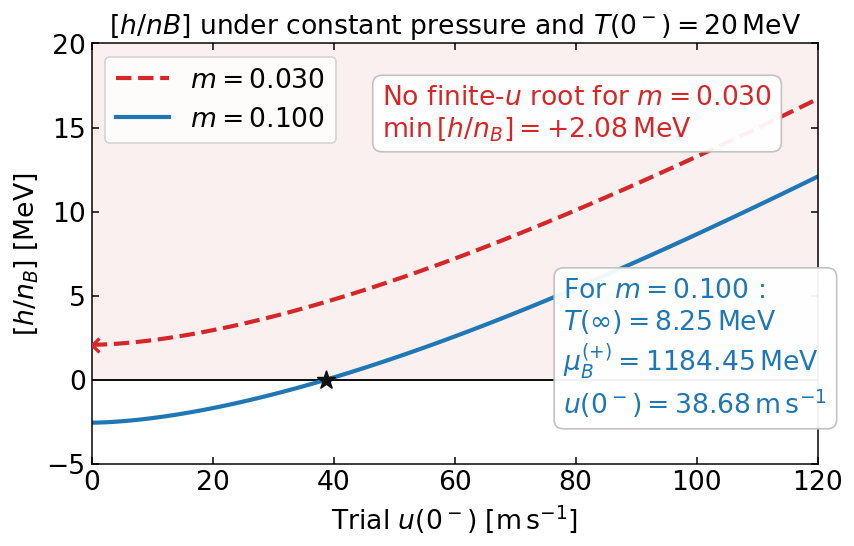

In [77]:
# Tunable plotting parameters
ISOBAR_ROOT_UPSTREAM_T_N_MEV = 20.0
ISOBAR_ROOT_METASTABILITIES = (0.03, 0.10)
ISOBAR_ROOT_COLORS = ("#d62728", "#1f77b4")
ISOBAR_ROOT_LINE_STYLES = ("--", "-")
ISOBAR_ROOT_INTERFACE_FRACTION_MODE = "LTE"
ISOBAR_ROOT_T_Q_LIMITS_MEV = (0.0, 20.0)
ISOBAR_ROOT_T_Q_GRID_COUNT = 121
ISOBAR_ROOT_U_N_LIMITS = (1.0e-30, 1.0e-2)
ISOBAR_ROOT_U_N_M_S_LIMITS = (0.0, 130.0)
ISOBAR_ROOT_MU_B_BRACKET_MEV = (700.0, 1700.0)
ISOBAR_ROOT_Y_LIMITS_MEV = (-5.0, 20.0)
ISOBAR_ROOT_FIGURE_SIZE = (7.2, 4.8)
ISOBAR_ROOT_FIGURE_DPI = 120
ISOBAR_ROOT_EXPORT_DPI = 180
ISOBAR_ROOT_LINE_WIDTH = 2.5
ISOBAR_ROOT_ZERO_COLOR = "#111111"
ISOBAR_ROOT_ZERO_LINE_STYLE = "-"
ISOBAR_ROOT_ZERO_LINE_WIDTH = 1.2
ISOBAR_ROOT_POSITIVE_SHADE_COLOR = "#f6d6d6"
ISOBAR_ROOT_POSITIVE_SHADE_ALPHA = 0.35
ISOBAR_ROOT_ENDPOINT_MARKER = "*"
ISOBAR_ROOT_ENDPOINT_MARKER_SIZE = 125
ISOBAR_ROOT_ENDPOINT_MARKER_COLOR = "#111111"
ISOBAR_ROOT_NO_SOLUTION_MARKER = "x"
ISOBAR_ROOT_NO_SOLUTION_MARKER_SIZE = 70
ISOBAR_ROOT_NO_SOLUTION_MARKER_LINE_WIDTH = 2.0
ISOBAR_ROOT_MARKER_ZORDER = 5
ISOBAR_ROOT_AXIS_LABEL_FONT_SIZE = 16
ISOBAR_ROOT_TITLE_FONT_SIZE = 16
ISOBAR_ROOT_TICK_LABEL_FONT_SIZE = 16
ISOBAR_ROOT_LEGEND_FONT_SIZE = 16
ISOBAR_ROOT_ANNOTATION_FONT_SIZE = 16
ISOBAR_ROOT_LEGEND_LOCATION = "upper left"
ISOBAR_ROOT_TICK_DIRECTION = "in"
ISOBAR_ROOT_TICK_LENGTH = 4.0
ISOBAR_ROOT_TICK_WIDTH = 0.9
ISOBAR_ROOT_SHOW_TOP_TICKS = True
ISOBAR_ROOT_SHOW_RIGHT_TICKS = True
ISOBAR_ROOT_SPINE_LINE_WIDTH = 0.9
ISOBAR_ROOT_NO_SOLUTION_TEXT_POSITION = (0.40, 0.78)
ISOBAR_ROOT_SOLUTION_TEXT_POSITION = (0.65, 0.12)
ISOBAR_ROOT_TEXT_BOX_STYLE = "round,pad=0.35"
ISOBAR_ROOT_TEXT_BOX_FACE_COLOR = "white"
ISOBAR_ROOT_TEXT_BOX_EDGE_COLOR = "0.75"
ISOBAR_ROOT_TEXT_BOX_ALPHA = 0.94
ISOBAR_ROOT_SUBPLOT_LEFT = 0.13
ISOBAR_ROOT_SUBPLOT_RIGHT = 0.97
ISOBAR_ROOT_SUBPLOT_BOTTOM = 0.15
ISOBAR_ROOT_SUBPLOT_TOP = 0.88
ISOBAR_ROOT_BACKGROUND_COLOR = "white"
ISOBAR_ROOT_PNG_FILENAME = "equilibrated-isobar-enthalpy-root-vs-u.png"
ISOBAR_ROOT_PDF_FILENAME = "equilibrated-isobar-enthalpy-root-vs-u.pdf"


def equilibrated_isobar_point(T_Q_MeV, nuclear_state):
    T_Q_MeV = float(T_Q_MeV)

    def pressure_residual(muB_Q_MeV):
        return float(
            phase_velocity.PQM(
                muB_Q_MeV,
                0.0,
                B14_MEV,
                T_Q_MeV,
                ms=MS_MEV,
            )
            - nuclear_state["P_N"]
        )

    muB_Q_MeV = float(
        brentq(
            pressure_residual,
            *ISOBAR_ROOT_MU_B_BRACKET_MEV,
            xtol=1.0e-8,
            rtol=1.0e-11,
        )
    )
    P_Q_MeV4 = float(phase_velocity.PQM(muB_Q_MeV, 0.0, B14_MEV, T_Q_MeV, ms=MS_MEV))
    e_Q_MeV4 = float(
        phase_velocity.edensQM(
            muB_Q_MeV,
            0.0,
            B14_MEV,
            T_Q_MeV,
            ms=MS_MEV,
            include_em=False,
        )
    )
    nB_Q_MeV3 = float(phase_velocity.nB_QM(muB_Q_MeV, 0.0, B14_MEV, T_Q_MeV, ms=MS_MEV))
    enthalpy_mismatch_MeV = float(
        (P_Q_MeV4 + e_Q_MeV4) / nB_Q_MeV3
        - nuclear_state["h_over_nB_N"]
    )
    A_radicand_MeV4 = float(
        108.0 * np.pi**2 * (P_Q_MeV4 + B14_MEV**4) - muB_Q_MeV**4
    )
    A_boundary = float(
        1.5 * np.sqrt(max(A_radicand_MeV4, 0.0)) / muB_Q_MeV**2
    )
    if T_Q_MeV == 0.0:
        u_N = 0.0
    else:
        endpoint = {
            "muB_Q": muB_Q_MeV,
            "T_Q": T_Q_MeV,
            "P_Q": P_Q_MeV4,
            "e_Q": e_Q_MeV4,
            "h_Q": P_Q_MeV4 + e_Q_MeV4,
            "nB_Q": nB_Q_MeV3,
            "U_bag": B14_MEV**4,
        }

        def analytic_velocity_fixed_point(log_u_N):
            u_N_trial = float(np.exp(log_u_N))
            endpoint["u_N"] = u_N_trial
            formula = phase_velocity._analytic_velocity_formula_from_endpoint(
                endpoint,
                nuclear_state,
                ANALYTIC_XI,
                interface_fraction_mode=ISOBAR_ROOT_INTERFACE_FRACTION_MODE,
            )
            return float(
                np.log(formula["u_N_formula_squared"])
                - 2.0 * log_u_N
            )

        log_u_N = float(
            brentq(
                analytic_velocity_fixed_point,
                np.log(ISOBAR_ROOT_U_N_LIMITS[0]),
                np.log(ISOBAR_ROOT_U_N_LIMITS[1]),
                xtol=1.0e-12,
                rtol=1.0e-12,
            )
        )
        u_N = float(np.exp(log_u_N))
    return muB_Q_MeV, enthalpy_mismatch_MeV, A_boundary, u_N


if ISOBAR_ROOT_UPSTREAM_T_N_MEV in critical_states_by_temperature:
    isobar_root_critical_state = critical_states_by_temperature[ISOBAR_ROOT_UPSTREAM_T_N_MEV]
else:
    isobar_root_critical_state = critical_state_at_temperature(ISOBAR_ROOT_UPSTREAM_T_N_MEV)

isobar_root_T_Q_values_MeV = np.linspace(
    *ISOBAR_ROOT_T_Q_LIMITS_MEV,
    ISOBAR_ROOT_T_Q_GRID_COUNT,
)
isobar_root_results = []
endpoint_guess = (
    float(isobar_root_critical_state["muB_crit_T_MeV"]),
    max(float(ISOBAR_ROOT_UPSTREAM_T_N_MEV), 1.0),
)
for metastability in ISOBAR_ROOT_METASTABILITIES:
    nuclear_state = enthalpy_upstream_state(float(metastability), isobar_root_critical_state)
    muB_Q_values_MeV = np.empty_like(isobar_root_T_Q_values_MeV)
    enthalpy_mismatch_values_MeV = np.empty_like(isobar_root_T_Q_values_MeV)
    A_boundary_values = np.empty_like(isobar_root_T_Q_values_MeV)
    u_N_values = np.empty_like(isobar_root_T_Q_values_MeV)
    for point_index, T_Q_MeV in enumerate(isobar_root_T_Q_values_MeV):
        (
            muB_Q_values_MeV[point_index],
            enthalpy_mismatch_values_MeV[point_index],
            A_boundary_values[point_index],
            u_N_values[point_index],
        ) = equilibrated_isobar_point(T_Q_MeV, nuclear_state)

    moving_solution = None
    if nuclear_state["enthalpy_gap_MeV"] <= 0.0:
        moving_solution = phase_velocity.analytic_velocity_bound(
            nuclear_state["muB_N"],
            ISOBAR_ROOT_UPSTREAM_T_N_MEV,
            B14_MEV,
            xi=ANALYTIC_XI,
            ms=MS_MEV,
            param=PARAM,
            NM_type=NM_TYPE,
            upB=ANALYTIC_UPB,
            initial_guess=endpoint_guess,
            interface_fraction_mode=ISOBAR_ROOT_INTERFACE_FRACTION_MODE,
        )
        endpoint_guess = (float(moving_solution["muB_Q"]), float(moving_solution["T_Q"]))

    isobar_root_results.append(
        {
            "metastability": float(metastability),
            "nuclear_state": nuclear_state,
            "muB_Q_values_MeV": muB_Q_values_MeV,
            "enthalpy_mismatch_values_MeV": enthalpy_mismatch_values_MeV,
            "A_boundary_values": A_boundary_values,
            "u_N_values": u_N_values,
            "u_N_values_m_s": u_N_values * const.m_per_sec,
            "moving_solution": moving_solution,
        }
    )

fig, ax = plt.subplots(
    figsize=ISOBAR_ROOT_FIGURE_SIZE,
    dpi=ISOBAR_ROOT_FIGURE_DPI,
    facecolor=ISOBAR_ROOT_BACKGROUND_COLOR,
)
ax.set_facecolor(ISOBAR_ROOT_BACKGROUND_COLOR)
ax.axhspan(
    0.0,
    ISOBAR_ROOT_Y_LIMITS_MEV[1],
    color=ISOBAR_ROOT_POSITIVE_SHADE_COLOR,
    alpha=ISOBAR_ROOT_POSITIVE_SHADE_ALPHA,
)
ax.axhline(
    0.0,
    color=ISOBAR_ROOT_ZERO_COLOR,
    linestyle=ISOBAR_ROOT_ZERO_LINE_STYLE,
    linewidth=ISOBAR_ROOT_ZERO_LINE_WIDTH,
)

diagnostic_rows = []
for result, color, line_style in zip(
    isobar_root_results,
    ISOBAR_ROOT_COLORS,
    ISOBAR_ROOT_LINE_STYLES,
):
    metastability = result["metastability"]
    nuclear_state = result["nuclear_state"]
    mismatch = result["enthalpy_mismatch_values_MeV"]
    A_boundary_values = result["A_boundary_values"]
    u_N_values_m_s = result["u_N_values_m_s"]
    moving_solution = result["moving_solution"]
    ax.plot(
        u_N_values_m_s,
        mismatch,
        color=color,
        linestyle=line_style,
        linewidth=ISOBAR_ROOT_LINE_WIDTH,
        label=rf"$m={metastability:.3f}$",
    )

    if moving_solution is None:
        minimum_index = int(np.nanargmin(mismatch))
        ax.scatter(
            (u_N_values_m_s[minimum_index],),
            (mismatch[minimum_index],),
            marker=ISOBAR_ROOT_NO_SOLUTION_MARKER,
            s=ISOBAR_ROOT_NO_SOLUTION_MARKER_SIZE,
            color=color,
            linewidths=ISOBAR_ROOT_NO_SOLUTION_MARKER_LINE_WIDTH,
            zorder=ISOBAR_ROOT_MARKER_ZORDER,
        )
        ax.text(
            *ISOBAR_ROOT_NO_SOLUTION_TEXT_POSITION,
            (
                rf"No finite-$u$ root for $m={metastability:.3f}$"
                + "\n"
                + rf"$\min\,[h/n_B]={np.nanmin(mismatch):+.2f}\,\mathrm{{MeV}}$"
            ),
            transform=ax.transAxes,
            fontsize=ISOBAR_ROOT_ANNOTATION_FONT_SIZE,
            color=color,
            bbox={
                "boxstyle": ISOBAR_ROOT_TEXT_BOX_STYLE,
                "facecolor": ISOBAR_ROOT_TEXT_BOX_FACE_COLOR,
                "edgecolor": ISOBAR_ROOT_TEXT_BOX_EDGE_COLOR,
                "alpha": ISOBAR_ROOT_TEXT_BOX_ALPHA,
            },
        )
        endpoint_T_Q_MeV = np.nan
        endpoint_muB_Q_MeV = np.nan
        endpoint_A_boundary = np.nan
        endpoint_speed_m_s = np.nan
        curve_zero_speed_m_s = np.nan
        velocity_closure_relative_error = np.nan
    else:
        endpoint_T_Q_MeV = float(moving_solution["T_Q"])
        endpoint_muB_Q_MeV = float(moving_solution["muB_Q"])
        endpoint_A_boundary = float(moving_solution["A_boundary"])
        eigenvalue_speed_m_s = float(moving_solution["u_N"] * const.m_per_sec)
        (
            endpoint_muB_Q_from_curve_MeV,
            endpoint_mismatch_MeV,
            endpoint_A_from_curve,
            endpoint_u_N_from_curve,
        ) = equilibrated_isobar_point(endpoint_T_Q_MeV, nuclear_state)
        endpoint_speed_m_s = float(endpoint_u_N_from_curve * const.m_per_sec)
        velocity_closure_relative_error = float(
            abs(endpoint_speed_m_s - eigenvalue_speed_m_s) / eigenvalue_speed_m_s
        )
        crossing_indices = np.flatnonzero(mismatch[:-1] * mismatch[1:] <= 0.0)
        if crossing_indices.size:
            crossing_index = int(crossing_indices[0])
            crossing_fraction = float(
                -mismatch[crossing_index]
                / (mismatch[crossing_index + 1] - mismatch[crossing_index])
            )
            curve_zero_speed_m_s = float(
                u_N_values_m_s[crossing_index]
                + crossing_fraction
                * (u_N_values_m_s[crossing_index + 1] - u_N_values_m_s[crossing_index])
            )
        else:
            curve_zero_speed_m_s = np.nan
        ax.scatter(
            (endpoint_speed_m_s,),
            (endpoint_mismatch_MeV,),
            marker=ISOBAR_ROOT_ENDPOINT_MARKER,
            s=ISOBAR_ROOT_ENDPOINT_MARKER_SIZE,
            color=ISOBAR_ROOT_ENDPOINT_MARKER_COLOR,
            zorder=ISOBAR_ROOT_MARKER_ZORDER,
        )
        ax.text(
            *ISOBAR_ROOT_SOLUTION_TEXT_POSITION,
            (
                rf"For $m={metastability:.3f}\ $:"
                + "\n"
                + rf"$T(\infty)={endpoint_T_Q_MeV:.2f}\,\mathrm{{MeV}}$"
                + "\n"
                + rf"$\mu_{{B}}^{{(+)}}={endpoint_muB_Q_MeV:.2f}\,\mathrm{{MeV}}$"
                + "\n"
                + rf"$u(0^-)={endpoint_speed_m_s:.2f}\,\mathrm{{m\,s^{{-1}}}}$"
            ),
            transform=ax.transAxes,
            fontsize=ISOBAR_ROOT_ANNOTATION_FONT_SIZE,
            color=color,
            bbox={
                "boxstyle": ISOBAR_ROOT_TEXT_BOX_STYLE,
                "facecolor": ISOBAR_ROOT_TEXT_BOX_FACE_COLOR,
                "edgecolor": ISOBAR_ROOT_TEXT_BOX_EDGE_COLOR,
                "alpha": ISOBAR_ROOT_TEXT_BOX_ALPHA,
            },
        )

    diagnostic_rows.append(
        {
            "T_N_MeV": ISOBAR_ROOT_UPSTREAM_T_N_MEV,
            "metastability": metastability,
            "enthalpy_gap_MeV": nuclear_state["enthalpy_gap_MeV"],
            "minimum_isobar_mismatch_MeV": float(np.nanmin(mismatch)),
            "moving_endpoint_exists": moving_solution is not None,
            "T_Q_endpoint_MeV": endpoint_T_Q_MeV,
            "muB_Q_endpoint_MeV": endpoint_muB_Q_MeV,
            "A_boundary_endpoint": endpoint_A_boundary,
            "u_N_m_s": endpoint_speed_m_s,
            "curve_zero_u_N_m_s": curve_zero_speed_m_s,
            "velocity_closure_relative_error": velocity_closure_relative_error,
        }
    )

ax.set_xlim(0,120)
ax.set_ylim(*ISOBAR_ROOT_Y_LIMITS_MEV)
ax.set_xlabel(
    r"Trial $u(0^-)$ [$\mathrm{m\,s^{-1}}$]",
    fontsize=ISOBAR_ROOT_AXIS_LABEL_FONT_SIZE,
)
ax.set_ylabel(
    r"$[h/n_B]$ [MeV]",
    fontsize=ISOBAR_ROOT_AXIS_LABEL_FONT_SIZE,
)
ax.set_title(
    rf"$[h/nB]$ under constant pressure and $T(0^-) = {ISOBAR_ROOT_UPSTREAM_T_N_MEV:g}\,\mathrm{{MeV}}$",
    fontsize=ISOBAR_ROOT_TITLE_FONT_SIZE,
)
ax.legend(loc=ISOBAR_ROOT_LEGEND_LOCATION, fontsize=ISOBAR_ROOT_LEGEND_FONT_SIZE)
ax.tick_params(
    direction=ISOBAR_ROOT_TICK_DIRECTION,
    top=ISOBAR_ROOT_SHOW_TOP_TICKS,
    right=ISOBAR_ROOT_SHOW_RIGHT_TICKS,
    length=ISOBAR_ROOT_TICK_LENGTH,
    width=ISOBAR_ROOT_TICK_WIDTH,
    labelsize=ISOBAR_ROOT_TICK_LABEL_FONT_SIZE,
)
for spine in ax.spines.values():
    spine.set_linewidth(ISOBAR_ROOT_SPINE_LINE_WIDTH)
fig.subplots_adjust(
    left=ISOBAR_ROOT_SUBPLOT_LEFT,
    right=ISOBAR_ROOT_SUBPLOT_RIGHT,
    bottom=ISOBAR_ROOT_SUBPLOT_BOTTOM,
    top=ISOBAR_ROOT_SUBPLOT_TOP,
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(
    OUTPUT_DIR / ISOBAR_ROOT_PNG_FILENAME,
    dpi=ISOBAR_ROOT_EXPORT_DPI,
    facecolor=ISOBAR_ROOT_BACKGROUND_COLOR,
)
fig.savefig(
    OUTPUT_DIR / ISOBAR_ROOT_PDF_FILENAME,
    facecolor=ISOBAR_ROOT_BACKGROUND_COLOR,
)
display(pd.DataFrame(diagnostic_rows))
plt.show()


## Numerical energy-conserving $n_K$ entropy profile

This example solves the absolute-$n_K$ energy-conserving front and plots the local quark-matter entropy per baryon $s_Q(x)/n_B(x)$.
The profile is reconstructed from $h=\mu_B n_B+\mu_K n_K+Ts$ and checked directly against `entropyQM` at representative points.


,success,u_N [m/s],T_Qstar [MeV],T_Q [MeV],s_Q/nB at 0+,s_Q/nB downstream,direct EOS max error
0,True,41.054391,26.922446,31.82403,2.087021,2.486354,1.199041e-14


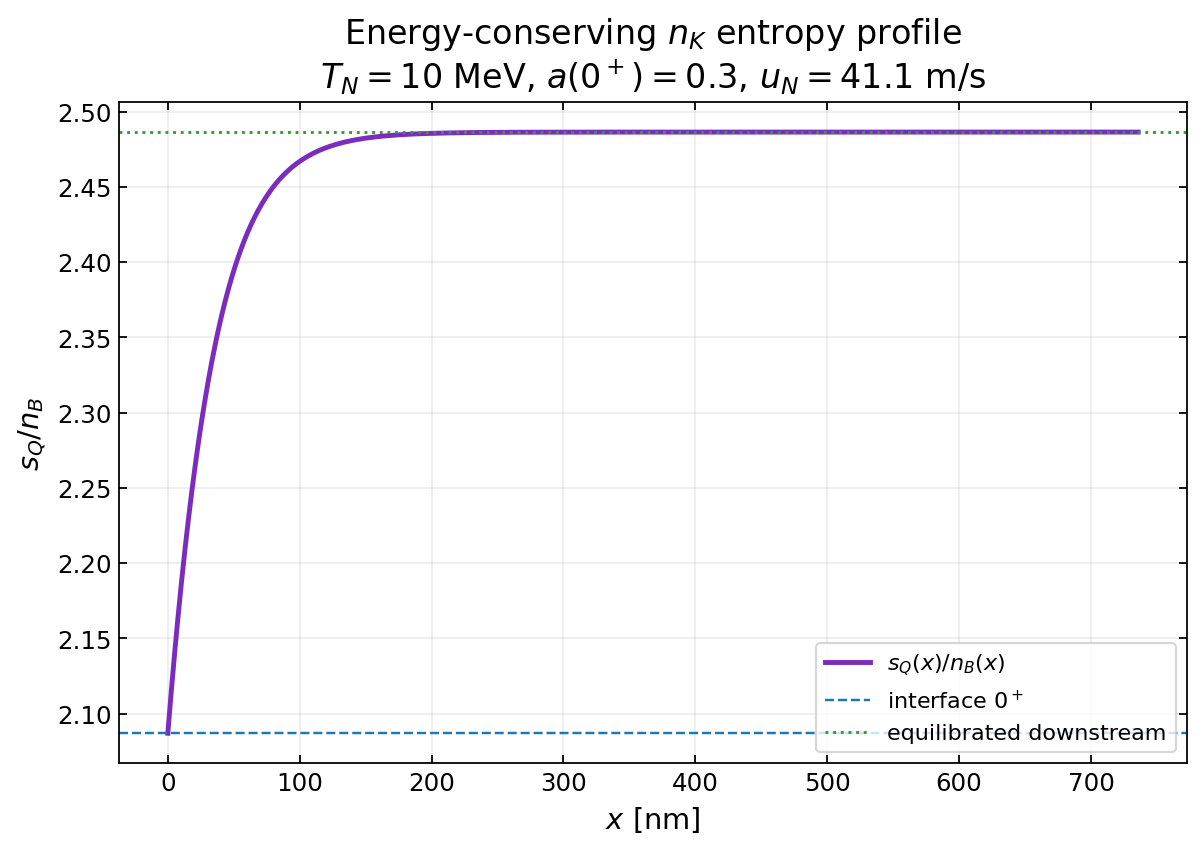

In [1]:
# Tunable plotting parameters
PROFILE_FIGURE_SIZE = (7.4, 5.2)
PROFILE_FIGURE_DPI = 160
PROFILE_EXPORT_DPI = 220
PROFILE_CONSTRAINED_LAYOUT = True
PROFILE_FIGURE_FACE_COLOR = "white"
PROFILE_AXES_FACE_COLOR = "white"
PROFILE_LINE_COLOR = "#7b2cbf"
PROFILE_LINE_STYLE = "-"
PROFILE_LINE_WIDTH = 2.2
PROFILE_INTERFACE_COLOR = "#1f77b4"
PROFILE_INTERFACE_LINE_STYLE = "--"
PROFILE_INTERFACE_LINE_WIDTH = 1.1
PROFILE_DOWNSTREAM_COLOR = "#2ca02c"
PROFILE_DOWNSTREAM_LINE_STYLE = ":"
PROFILE_DOWNSTREAM_LINE_WIDTH = 1.3
PROFILE_GRID_ENABLED = True
PROFILE_GRID_ALPHA = 0.22
PROFILE_X_SCALE = "linear"
PROFILE_Y_SCALE = "linear"
PROFILE_TITLE_FONT_SIZE = 15
PROFILE_AXIS_LABEL_FONT_SIZE = 13
PROFILE_TICK_LABEL_FONT_SIZE = 11
PROFILE_LEGEND_FONT_SIZE = 10
PROFILE_LEGEND_LOCATION = "lower right"
PROFILE_TICK_DIRECTION = "in"
PROFILE_TICKS_TOP = True
PROFILE_TICKS_RIGHT = True
PROFILE_X_LABEL = r"$x$ [nm]"
PROFILE_Y_LABEL = r"$s_Q/n_B$"
PROFILE_OUTPUT_DIR = "local_analysis_results/26SU-8"
PROFILE_PNG_FILENAME = "energy-conserving-nK-entropy-per-baryon-profile.png"
PROFILE_PDF_FILENAME = "energy-conserving-nK-entropy-per-baryon-profile.pdf"

# Tunable solver parameters
PROFILE_T_N_MEV = 10.0
PROFILE_NB_N_OVER_N0 = 3.0
PROFILE_B14_MEV = 180.0
PROFILE_A_QSTAR = 0.3
PROFILE_MS_MEV = 0.0
PROFILE_TAIL_EPS = 1.0e-5
PROFILE_N_MESH = 40
PROFILE_TOL_BVP = 2.0e-3
PROFILE_MAX_NODES = 1200
PROFILE_JB_GUESS = 0.02
PROFILE_JB_BOUNDS = (1.0e-5, 2.0)
PROFILE_VALIDATION_POINT_COUNT = 5
PROFILE_ENTROPY_VALIDATION_ATOL = 1.0e-9
FM_PER_NM = 1.0e6

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from pathlib import Path

import RMFsolver.constants as const
import RMFsolver.phase_velocity as phase_velocity

profile_n0 = 0.16 * const.MeV_fm**3
profile_result = phase_velocity.solve_front_energy_conserving_nK(
    T=PROFILE_T_N_MEV,
    nB_N=PROFILE_NB_N_OVER_N0 * profile_n0,
    B_one_forth=PROFILE_B14_MEV,
    aQstar=PROFILE_A_QSTAR,
    ms=PROFILE_MS_MEV,
    tail_eps=PROFILE_TAIL_EPS,
    n_mesh=PROFILE_N_MESH,
    tol_bvp=PROFILE_TOL_BVP,
    max_nodes=PROFILE_MAX_NODES,
    jB_guess=PROFILE_JB_GUESS,
    jB_bounds=PROFILE_JB_BOUNDS,
    return_profile=True,
    verb=False,
)
if not bool(profile_result.get("success")):
    raise RuntimeError(profile_result.get("message", "energy-conserving nK solve failed"))

profile_x_nm = (
    np.asarray(profile_result["x"], dtype=float) * const.MeV_fm / FM_PER_NM
)
profile_nK = np.asarray(profile_result["nK"], dtype=float)
profile_nB = np.asarray(profile_result["nB"], dtype=float)
profile_muB = np.asarray(profile_result["muB"], dtype=float)
profile_muK = np.asarray(profile_result["muK"], dtype=float)
profile_T = np.asarray(profile_result["T_profile"], dtype=float)
profile_h = np.asarray(profile_result["h_profile"], dtype=float)
profile_a = profile_nK / profile_nB
profile_entropy_per_baryon = (
    profile_h / profile_nB - profile_muB - profile_muK * profile_a
) / profile_T

profile_validation_indices = np.unique(
    np.linspace(
        0,
        profile_x_nm.size - 1,
        PROFILE_VALIDATION_POINT_COUNT,
        dtype=int,
    )
)
profile_entropy_direct = np.asarray(
    [
        phase_velocity.entropyQM(
            profile_muB[index],
            profile_muK[index],
            PROFILE_B14_MEV,
            profile_T[index],
            ms=PROFILE_MS_MEV,
        )
        / profile_nB[index]
        for index in profile_validation_indices
    ],
    dtype=float,
)
profile_entropy_validation_error = float(
    np.max(
        np.abs(
            profile_entropy_per_baryon[profile_validation_indices]
            - profile_entropy_direct
        )
    )
)
if profile_entropy_validation_error > PROFILE_ENTROPY_VALIDATION_ATOL:
    raise RuntimeError(
        "Entropy reconstruction failed direct EOS validation: "
        f"max error={profile_entropy_validation_error:.3e}"
    )

profile_summary = pd.DataFrame(
    [
        {
            "success": bool(profile_result["success"]),
            "u_N [m/s]": float(profile_result["u_N"]) * const.m_per_sec,
            "T_Qstar [MeV]": float(profile_T[0]),
            "T_Q [MeV]": float(profile_result["T_Q"]),
            "s_Q/nB at 0+": float(profile_entropy_per_baryon[0]),
            "s_Q/nB downstream": float(profile_entropy_per_baryon[-1]),
            "direct EOS max error": profile_entropy_validation_error,
        }
    ]
)
display(profile_summary)

fig, ax = plt.subplots(
    figsize=PROFILE_FIGURE_SIZE,
    dpi=PROFILE_FIGURE_DPI,
    constrained_layout=PROFILE_CONSTRAINED_LAYOUT,
    facecolor=PROFILE_FIGURE_FACE_COLOR,
)
ax.set_facecolor(PROFILE_AXES_FACE_COLOR)
ax.plot(
    profile_x_nm,
    profile_entropy_per_baryon,
    color=PROFILE_LINE_COLOR,
    linestyle=PROFILE_LINE_STYLE,
    linewidth=PROFILE_LINE_WIDTH,
    label=r"$s_Q(x)/n_B(x)$",
)
ax.axhline(
    profile_entropy_per_baryon[0],
    color=PROFILE_INTERFACE_COLOR,
    linestyle=PROFILE_INTERFACE_LINE_STYLE,
    linewidth=PROFILE_INTERFACE_LINE_WIDTH,
    label=r"interface $0^+$",
)
ax.axhline(
    profile_entropy_per_baryon[-1],
    color=PROFILE_DOWNSTREAM_COLOR,
    linestyle=PROFILE_DOWNSTREAM_LINE_STYLE,
    linewidth=PROFILE_DOWNSTREAM_LINE_WIDTH,
    label=r"equilibrated downstream",
)
ax.set_xscale(PROFILE_X_SCALE)
ax.set_yscale(PROFILE_Y_SCALE)
ax.set_xlabel(PROFILE_X_LABEL, fontsize=PROFILE_AXIS_LABEL_FONT_SIZE)
ax.set_ylabel(PROFILE_Y_LABEL, fontsize=PROFILE_AXIS_LABEL_FONT_SIZE)
ax.set_title(
    "Energy-conserving $n_K$ entropy profile\n"
    f"$T_N={PROFILE_T_N_MEV:g}$ MeV, "
    f"$a(0^+)={PROFILE_A_QSTAR:g}$, "
    f"$u_N={float(profile_result['u_N']) * const.m_per_sec:.1f}$ m/s",
    fontsize=PROFILE_TITLE_FONT_SIZE,
)
ax.grid(PROFILE_GRID_ENABLED, alpha=PROFILE_GRID_ALPHA)
ax.tick_params(
    labelsize=PROFILE_TICK_LABEL_FONT_SIZE,
    direction=PROFILE_TICK_DIRECTION,
    top=PROFILE_TICKS_TOP,
    right=PROFILE_TICKS_RIGHT,
)
ax.legend(fontsize=PROFILE_LEGEND_FONT_SIZE, loc=PROFILE_LEGEND_LOCATION)

PROFILE_OUTPUT_DIR = Path(PROFILE_OUTPUT_DIR)
PROFILE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(
    PROFILE_OUTPUT_DIR / PROFILE_PNG_FILENAME,
    dpi=PROFILE_EXPORT_DPI,
    facecolor=PROFILE_FIGURE_FACE_COLOR,
)
fig.savefig(
    PROFILE_OUTPUT_DIR / PROFILE_PDF_FILENAME,
    facecolor=PROFILE_FIGURE_FACE_COLOR,
)
plt.show()


,grid shape,finite velocity cells,failed cells,timed-out cells,velocity min [m/s],velocity max [m/s],TQstar [MeV]
0,"(30, 20)",528,72,0,0.237932,545.413751,0.5


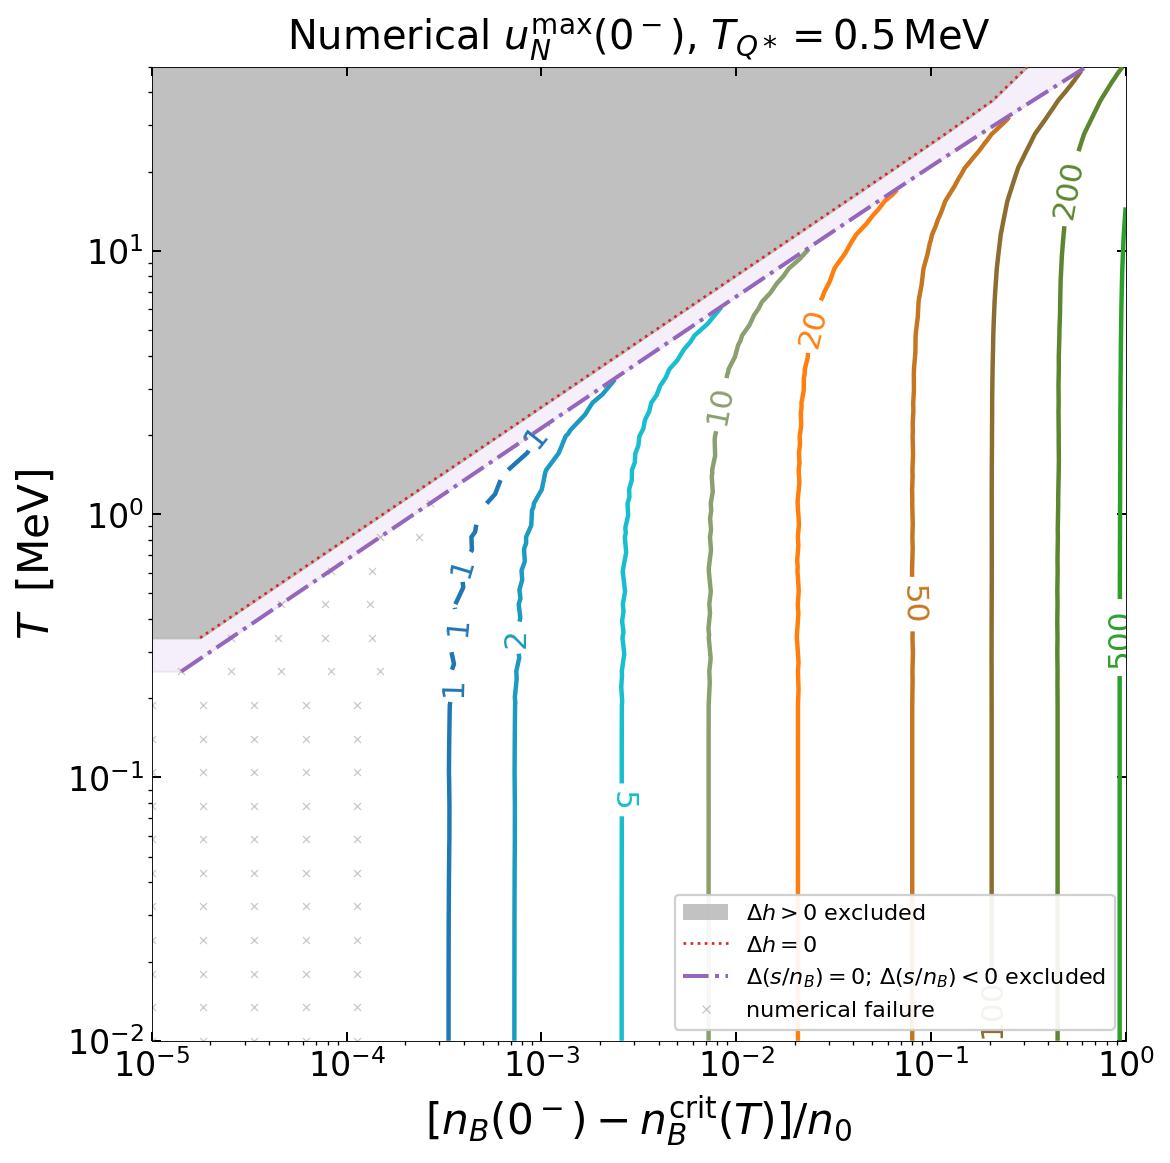

In [2]:
# Tunable plotting parameters
NUMERICAL_CONTOUR_DATA_PATH = "new_paper_calculations/26-07-20/uNmax-logTm-entropy-safe.npy"
NUMERICAL_CONTOUR_OUTPUT_DIR = "local_analysis_results/26SU-8"
NUMERICAL_CONTOUR_PNG_FILENAME = "numerical-uNmax-logTm-entropy-safe.png"
NUMERICAL_CONTOUR_PDF_FILENAME = "numerical-uNmax-logTm-entropy-safe.pdf"
NUMERICAL_CONTOUR_FIGURE_SIZE = (7.2, 7.2)
NUMERICAL_CONTOUR_FIGURE_DPI = 160
NUMERICAL_CONTOUR_EXPORT_DPI = 220
NUMERICAL_CONTOUR_CONSTRAINED_LAYOUT = True
NUMERICAL_CONTOUR_BACKGROUND_COLOR = "white"
NUMERICAL_CONTOUR_X_LIMITS = (1.0e-5, 1.0)
NUMERICAL_CONTOUR_X_SCALE = "log"
NUMERICAL_CONTOUR_Y_LIMITS_MEV = (1.0e-2, 50.0)
NUMERICAL_CONTOUR_Y_SCALE = "log"
NUMERICAL_CONTOUR_BOX_ASPECT = 1.0
NUMERICAL_CONTOUR_LEVELS_M_S = (1.0, 2.0, 5.0, 10.0, 20.0, 50.0, 100.0, 200.0, 500.0)
NUMERICAL_CONTOUR_CMAP_NAME = "numerical_linear_contour_palette"
NUMERICAL_CONTOUR_CMAP_ANCHORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c")
NUMERICAL_CONTOUR_LINE_STYLE = "-"
NUMERICAL_CONTOUR_LINE_WIDTH = 2.0
NUMERICAL_CONTOUR_LABEL_FONT_SIZE = 14
NUMERICAL_CONTOUR_LABEL_INLINE = True
NUMERICAL_CONTOUR_LABEL_INLINE_SPACING = 5
NUMERICAL_CONTOUR_LABEL_FORMAT = "{:.0f}"
NUMERICAL_CONTOUR_ZORDER = 3
NUMERICAL_CONTOUR_GAP_BOUNDARY_COLOR = "#d62728"
NUMERICAL_CONTOUR_GAP_BOUNDARY_LINE_STYLE = ":"
NUMERICAL_CONTOUR_GAP_BOUNDARY_LINE_WIDTH = 1.2
NUMERICAL_CONTOUR_ENTROPY_BOUNDARY_COLOR = "#9467bd"
NUMERICAL_CONTOUR_ENTROPY_BOUNDARY_LINE_STYLE = "-."
NUMERICAL_CONTOUR_ENTROPY_BOUNDARY_LINE_WIDTH = 1.8
NUMERICAL_CONTOUR_BOUNDARY_ZORDER = 4
NUMERICAL_CONTOUR_GAP_SHADE_COLOR = "0.72"
NUMERICAL_CONTOUR_GAP_SHADE_ALPHA = 0.85
NUMERICAL_CONTOUR_ENTROPY_SHADE_COLOR = "#9467bd"
NUMERICAL_CONTOUR_ENTROPY_SHADE_ALPHA = 0.10
NUMERICAL_CONTOUR_SHADE_ZORDER = 0
NUMERICAL_CONTOUR_SHOW_FAILURE_MARKERS = True
NUMERICAL_CONTOUR_FAILURE_MARKER = "x"
NUMERICAL_CONTOUR_FAILURE_MARKER_COLOR = "0.55"
NUMERICAL_CONTOUR_FAILURE_MARKER_SIZE = 10.0
NUMERICAL_CONTOUR_FAILURE_MARKER_LINE_WIDTH = 0.6
NUMERICAL_CONTOUR_FAILURE_MARKER_ALPHA = 0.45
NUMERICAL_CONTOUR_FAILURE_MARKER_ZORDER = 2
NUMERICAL_CONTOUR_TITLE_FONT_SIZE = 18
NUMERICAL_CONTOUR_TITLE_PAD = 8
NUMERICAL_CONTOUR_AXIS_LABEL_FONT_SIZE = 19
NUMERICAL_CONTOUR_TICK_LABEL_FONT_SIZE = 15
NUMERICAL_CONTOUR_TICK_DIRECTION = "in"
NUMERICAL_CONTOUR_TICKS_TOP = True
NUMERICAL_CONTOUR_TICKS_RIGHT = True
NUMERICAL_CONTOUR_TICK_LENGTH = 4.0
NUMERICAL_CONTOUR_TICK_WIDTH = 0.9
NUMERICAL_CONTOUR_SPINE_LINE_WIDTH = 0.4
NUMERICAL_CONTOUR_LEGEND_FONT_SIZE = 10
NUMERICAL_CONTOUR_LEGEND_LOCATION = "lower right"
NUMERICAL_CONTOUR_LEGEND_FRAME_ALPHA = 0.92
NUMERICAL_CONTOUR_X_LABEL = r"$[n_B(0^-)-n_B^{\rm crit}(T)]/n_0$"
NUMERICAL_CONTOUR_Y_LABEL = r"$T\;\; \rm{[MeV]}$"
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from pathlib import Path
numerical_data_path = Path(NUMERICAL_CONTOUR_DATA_PATH)
numerical_output_dir = Path(NUMERICAL_CONTOUR_OUTPUT_DIR)
numerical_payload = np.load(numerical_data_path, allow_pickle=True).item()
numerical_expected_metadata = {
    "temperature_axis_scale": "log",
    "metastability_axis_scale": "log",
    "mesh_layout": "adaptive_logT_logm_entropy_safe",
    "root_method": "solve_bvp_uNmax_nK_parameter_1d",
}
for numerical_key, numerical_expected in numerical_expected_metadata.items():
    if numerical_payload.get(numerical_key) != numerical_expected:
        raise ValueError(
            f"Expected {numerical_key}={numerical_expected!r} in {numerical_data_path}, "
            f"got {numerical_payload.get(numerical_key)!r}"
        )
numerical_m_grid = np.asarray(numerical_payload["metastability_grid"], dtype=float)
numerical_T_grid_MeV = np.asarray(numerical_payload["temperature_grid"], dtype=float)
numerical_velocity_grid_m_s = np.asarray(numerical_payload["velocity_grid_m_s"], dtype=float)
numerical_status_grid = np.asarray(numerical_payload["status_grid"], dtype=int)
if not (
    numerical_m_grid.shape
    == numerical_T_grid_MeV.shape
    == numerical_velocity_grid_m_s.shape
    == numerical_status_grid.shape
):
    raise ValueError("Saved numerical grids do not have matching shapes")
numerical_finite = (
    np.isfinite(numerical_m_grid)
    & np.isfinite(numerical_T_grid_MeV)
    & np.isfinite(numerical_velocity_grid_m_s)
    & (numerical_velocity_grid_m_s > 0.0)
)
if not np.any(numerical_finite):
    raise ValueError(f"No finite positive numerical velocities in {numerical_data_path}")
numerical_timeout_grid = np.asarray(numerical_payload["point_timed_out_grid"], dtype=bool)
display(
    pd.DataFrame(
        [{
            "grid shape": str(numerical_velocity_grid_m_s.shape),
            "finite velocity cells": int(np.count_nonzero(numerical_finite)),
            "failed cells": int(numerical_velocity_grid_m_s.size - np.count_nonzero(numerical_finite)),
            "timed-out cells": int(np.count_nonzero(numerical_timeout_grid)),
            "velocity min [m/s]": float(np.nanmin(numerical_velocity_grid_m_s[numerical_finite])),
            "velocity max [m/s]": float(np.nanmax(numerical_velocity_grid_m_s[numerical_finite])),
            "TQstar [MeV]": float(numerical_payload["TQstar_target_MeV"]),
        }]
    )
)
numerical_rows, numerical_cols = numerical_velocity_grid_m_s.shape
numerical_triangles = []
for numerical_i in range(numerical_rows - 1):
    for numerical_j in range(numerical_cols - 1):
        numerical_a = numerical_i * numerical_cols + numerical_j
        numerical_b = numerical_a + 1
        numerical_c = numerical_a + numerical_cols + 1
        numerical_d = numerical_a + numerical_cols
        numerical_triangles.extend(((numerical_a, numerical_b, numerical_c), (numerical_a, numerical_c, numerical_d)))
numerical_triangles = np.asarray(numerical_triangles, dtype=int)
numerical_m_flat = numerical_m_grid.ravel()
numerical_T_flat = numerical_T_grid_MeV.ravel()
numerical_velocity_flat = numerical_velocity_grid_m_s.ravel()
numerical_point_valid = (
    np.isfinite(numerical_m_flat)
    & (numerical_m_flat > 0.0)
    & np.isfinite(numerical_T_flat)
    & (numerical_T_flat > 0.0)
    & np.isfinite(numerical_velocity_flat)
    & (numerical_velocity_flat > 0.0)
)
numerical_triangle_mask = np.any(~numerical_point_valid[numerical_triangles], axis=1)
numerical_triangulation = mtri.Triangulation(
    numerical_m_flat,
    numerical_T_flat,
    triangles=numerical_triangles,
)
numerical_triangulation.set_mask(numerical_triangle_mask)
numerical_cmap = LinearSegmentedColormap.from_list(
    NUMERICAL_CONTOUR_CMAP_NAME,
    NUMERICAL_CONTOUR_CMAP_ANCHORS,
    N=len(NUMERICAL_CONTOUR_LEVELS_M_S),
)
numerical_colors = tuple(
    numerical_cmap(np.linspace(0.0, 1.0, len(NUMERICAL_CONTOUR_LEVELS_M_S)))
)
numerical_level_to_color = dict(zip(NUMERICAL_CONTOUR_LEVELS_M_S, numerical_colors))
numerical_available_levels = [
    float(numerical_level)
    for numerical_level in NUMERICAL_CONTOUR_LEVELS_M_S
    if np.nanmin(numerical_velocity_flat[numerical_point_valid])
    <= float(numerical_level)
    <= np.nanmax(numerical_velocity_flat[numerical_point_valid])
]
numerical_fig, numerical_ax = plt.subplots(
    figsize=NUMERICAL_CONTOUR_FIGURE_SIZE,
    dpi=NUMERICAL_CONTOUR_FIGURE_DPI,
    constrained_layout=NUMERICAL_CONTOUR_CONSTRAINED_LAYOUT,
    facecolor=NUMERICAL_CONTOUR_BACKGROUND_COLOR,
)
numerical_ax.set_facecolor(NUMERICAL_CONTOUR_BACKGROUND_COLOR)
numerical_ax.set_xscale(NUMERICAL_CONTOUR_X_SCALE)
numerical_ax.set_yscale(NUMERICAL_CONTOUR_Y_SCALE)
numerical_ax.set_xlim(*NUMERICAL_CONTOUR_X_LIMITS)
numerical_ax.set_ylim(*NUMERICAL_CONTOUR_Y_LIMITS_MEV)
numerical_ax.set_box_aspect(NUMERICAL_CONTOUR_BOX_ASPECT)
numerical_temperature_values_MeV = np.asarray(numerical_payload["temperature_values"], dtype=float)
numerical_gap_boundary = np.asarray(numerical_payload["gap_boundary_metastability"], dtype=float)
numerical_entropy_boundary = np.asarray(numerical_payload["entropy_boundary_metastability"], dtype=float)
numerical_entropy_boundary_finite = (
    np.isfinite(numerical_temperature_values_MeV)
    & np.isfinite(numerical_entropy_boundary)
    & (numerical_entropy_boundary > NUMERICAL_CONTOUR_X_LIMITS[0])
)
if np.any(numerical_entropy_boundary_finite):
    numerical_ax.fill_betweenx(
        numerical_temperature_values_MeV[numerical_entropy_boundary_finite],
        NUMERICAL_CONTOUR_X_LIMITS[0],
        numerical_entropy_boundary[numerical_entropy_boundary_finite],
        color=NUMERICAL_CONTOUR_ENTROPY_SHADE_COLOR,
        alpha=NUMERICAL_CONTOUR_ENTROPY_SHADE_ALPHA,
        zorder=NUMERICAL_CONTOUR_SHADE_ZORDER,
    )
numerical_gap_boundary_finite = (
    np.isfinite(numerical_temperature_values_MeV)
    & np.isfinite(numerical_gap_boundary)
    & (numerical_gap_boundary > NUMERICAL_CONTOUR_X_LIMITS[0])
)
if np.any(numerical_gap_boundary_finite):
    numerical_ax.fill_betweenx(
        numerical_temperature_values_MeV[numerical_gap_boundary_finite],
        NUMERICAL_CONTOUR_X_LIMITS[0],
        numerical_gap_boundary[numerical_gap_boundary_finite],
        color=NUMERICAL_CONTOUR_GAP_SHADE_COLOR,
        alpha=NUMERICAL_CONTOUR_GAP_SHADE_ALPHA,
        zorder=NUMERICAL_CONTOUR_SHADE_ZORDER + 1,
    )
numerical_contour = numerical_ax.tricontour(
    numerical_triangulation,
    np.nan_to_num(numerical_velocity_flat, nan=0.0),
    levels=numerical_available_levels,
    colors=[numerical_level_to_color[level] for level in numerical_available_levels],
    linewidths=NUMERICAL_CONTOUR_LINE_WIDTH,
    linestyles=NUMERICAL_CONTOUR_LINE_STYLE,
    zorder=NUMERICAL_CONTOUR_ZORDER,
)
numerical_ax.clabel(
    numerical_contour,
    inline=NUMERICAL_CONTOUR_LABEL_INLINE,
    inline_spacing=NUMERICAL_CONTOUR_LABEL_INLINE_SPACING,
    fontsize=NUMERICAL_CONTOUR_LABEL_FONT_SIZE,
    fmt=lambda numerical_value: NUMERICAL_CONTOUR_LABEL_FORMAT.format(numerical_value),
)
if np.any(numerical_gap_boundary_finite):
    numerical_ax.plot(
        numerical_gap_boundary[numerical_gap_boundary_finite],
        numerical_temperature_values_MeV[numerical_gap_boundary_finite],
        color=NUMERICAL_CONTOUR_GAP_BOUNDARY_COLOR,
        linestyle=NUMERICAL_CONTOUR_GAP_BOUNDARY_LINE_STYLE,
        linewidth=NUMERICAL_CONTOUR_GAP_BOUNDARY_LINE_WIDTH,
        zorder=NUMERICAL_CONTOUR_BOUNDARY_ZORDER,
    )
if np.any(numerical_entropy_boundary_finite):
    numerical_ax.plot(
        numerical_entropy_boundary[numerical_entropy_boundary_finite],
        numerical_temperature_values_MeV[numerical_entropy_boundary_finite],
        color=NUMERICAL_CONTOUR_ENTROPY_BOUNDARY_COLOR,
        linestyle=NUMERICAL_CONTOUR_ENTROPY_BOUNDARY_LINE_STYLE,
        linewidth=NUMERICAL_CONTOUR_ENTROPY_BOUNDARY_LINE_WIDTH,
        zorder=NUMERICAL_CONTOUR_BOUNDARY_ZORDER,
    )
numerical_failure = (
    np.isfinite(numerical_m_grid)
    & np.isfinite(numerical_T_grid_MeV)
    & ~np.isfinite(numerical_velocity_grid_m_s)
)
if NUMERICAL_CONTOUR_SHOW_FAILURE_MARKERS and np.any(numerical_failure):
    numerical_ax.scatter(
        numerical_m_grid[numerical_failure],
        numerical_T_grid_MeV[numerical_failure],
        marker=NUMERICAL_CONTOUR_FAILURE_MARKER,
        color=NUMERICAL_CONTOUR_FAILURE_MARKER_COLOR,
        s=NUMERICAL_CONTOUR_FAILURE_MARKER_SIZE,
        linewidths=NUMERICAL_CONTOUR_FAILURE_MARKER_LINE_WIDTH,
        alpha=NUMERICAL_CONTOUR_FAILURE_MARKER_ALPHA,
        zorder=NUMERICAL_CONTOUR_FAILURE_MARKER_ZORDER,
    )
numerical_ax.set_title(
    rf"Numerical $u_N^{{\max}}(0^-)$, $T_{{Q*}}={float(numerical_payload['TQstar_target_MeV']):g}\,\mathrm{{MeV}}$",
    fontsize=NUMERICAL_CONTOUR_TITLE_FONT_SIZE,
    pad=NUMERICAL_CONTOUR_TITLE_PAD,
)
numerical_ax.set_xlabel(NUMERICAL_CONTOUR_X_LABEL, fontsize=NUMERICAL_CONTOUR_AXIS_LABEL_FONT_SIZE)
numerical_ax.set_ylabel(NUMERICAL_CONTOUR_Y_LABEL, fontsize=NUMERICAL_CONTOUR_AXIS_LABEL_FONT_SIZE)
numerical_ax.tick_params(
    direction=NUMERICAL_CONTOUR_TICK_DIRECTION,
    top=NUMERICAL_CONTOUR_TICKS_TOP,
    right=NUMERICAL_CONTOUR_TICKS_RIGHT,
    length=NUMERICAL_CONTOUR_TICK_LENGTH,
    width=NUMERICAL_CONTOUR_TICK_WIDTH,
    labelsize=NUMERICAL_CONTOUR_TICK_LABEL_FONT_SIZE,
)
for numerical_spine in numerical_ax.spines.values():
    numerical_spine.set_linewidth(NUMERICAL_CONTOUR_SPINE_LINE_WIDTH)
numerical_legend_handles = [
    Patch(
        facecolor=NUMERICAL_CONTOUR_GAP_SHADE_COLOR,
        alpha=NUMERICAL_CONTOUR_GAP_SHADE_ALPHA,
        label=r"$\Delta h>0$ excluded",
    ),
    Line2D(
        (0.0,),
        (0.0,),
        color=NUMERICAL_CONTOUR_GAP_BOUNDARY_COLOR,
        linestyle=NUMERICAL_CONTOUR_GAP_BOUNDARY_LINE_STYLE,
        linewidth=NUMERICAL_CONTOUR_GAP_BOUNDARY_LINE_WIDTH,
        label=r"$\Delta h=0$",
    ),
    Line2D(
        (0.0,),
        (0.0,),
        color=NUMERICAL_CONTOUR_ENTROPY_BOUNDARY_COLOR,
        linestyle=NUMERICAL_CONTOUR_ENTROPY_BOUNDARY_LINE_STYLE,
        linewidth=NUMERICAL_CONTOUR_ENTROPY_BOUNDARY_LINE_WIDTH,
        label=r"$\Delta(s/n_B)=0$; $\Delta(s/n_B)<0$ excluded",
    ),
]
if NUMERICAL_CONTOUR_SHOW_FAILURE_MARKERS and np.any(numerical_failure):
    numerical_legend_handles.append(
        Line2D(
            (0.0,),
            (0.0,),
            color=NUMERICAL_CONTOUR_FAILURE_MARKER_COLOR,
            marker=NUMERICAL_CONTOUR_FAILURE_MARKER,
            linestyle="None",
            markersize=np.sqrt(NUMERICAL_CONTOUR_FAILURE_MARKER_SIZE),
            markeredgewidth=NUMERICAL_CONTOUR_FAILURE_MARKER_LINE_WIDTH,
            alpha=NUMERICAL_CONTOUR_FAILURE_MARKER_ALPHA,
            label="numerical failure",
        )
    )
numerical_ax.legend(
    handles=numerical_legend_handles,
    fontsize=NUMERICAL_CONTOUR_LEGEND_FONT_SIZE,
    loc=NUMERICAL_CONTOUR_LEGEND_LOCATION,
    framealpha=NUMERICAL_CONTOUR_LEGEND_FRAME_ALPHA,
)
numerical_output_dir.mkdir(parents=True, exist_ok=True)
numerical_fig.savefig(
    numerical_output_dir / NUMERICAL_CONTOUR_PNG_FILENAME,
    dpi=NUMERICAL_CONTOUR_EXPORT_DPI,
    facecolor=NUMERICAL_CONTOUR_BACKGROUND_COLOR,
)
numerical_fig.savefig(
    numerical_output_dir / NUMERICAL_CONTOUR_PDF_FILENAME,
    facecolor=NUMERICAL_CONTOUR_BACKGROUND_COLOR,
)
plt.show()
